In [6]:
import pandas as pd
import numpy as np
import glob

# Buscar el archivo CSV
archivos_csv = glob.glob("/content/*.csv")

# Cargar el dataset
df = pd.read_csv(
    archivos_csv[0],
    encoding="utf-8-sig"
)

# Confirmar la carga
print("DATASET CARGADO CORRECTAMENTE")
print("--------------------------------")
print("Nombre:", archivos_csv[0].split("/")[-1])
print("Cantidad de registros:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])

# Mostrar primeras filas
display(df.head())

DATASET CARGADO CORRECTAMENTE
--------------------------------
Nombre: Connacionales_inscritos_en_el_Registro_Ciudadano_en_Línea_20261107.csv
Cantidad de registros: 1996461
Cantidad de columnas: 14


,País,Código ISO país,Ciudad de Residencia,Oficina de circunscripción consular,Edad (años),Área Conocimiento,Nivel Académico,Estado civil,Sexo,Pertenencia étnica,Ciudad de Nacimiento,Localización,Fecha de Registro,Cantidad de personas
0,AFGANISTAN,AFG,BADAKHSHAN/BUCHI,C. NUEVA DELHI,37,"ECONOMÍA, ADMINISTRACIÓN CONTADURIA Y AFINES",SIN INFORMACIÓN,DESCONOCIDO,FEMENINO,OTRO,COLOMBIA/SANTANDER/BUCARAMANGA,"(33.93911, 67.709953)",2018-10,1
1,ALBANIA,ALB,TIRANE/FACESH,C. ROMA,-1,NO INDICA,BACHILLERATO,DESCONOCIDO,FEMENINO,SIN ETNIA REGISTRADA,COLOMBIA/ANTIOQUIA/ITAGUI,"(41.153332, 20.168331)",2015-10,1
2,ALBANIA,ALB,TIRANE/TIRANA,C. ROMA,7,CIENCIAS DE LA SALUD,SIN INFORMACIÓN,SOLTERO,FEMENINO,NINGUNA,COLOMBIA/CUNDINAMARCA/BOGOTA,"(41.153332, 20.168331)",2018-12,1
3,ALBANIA,ALB,TIRANE/TIRANA,C. ROMA,24,NINGUNA,BACHILLERATO,SOLTERO,FEMENINO,OTRO,ALBANIA/TIRANE/TIRANA,"(41.153332, 20.168331)",2024-10,1
4,ALBANIA,ALB,TIRANE/TIRANA,C. ROMA,46,"INGENIERÍA, ARQUITECTURA Y AFINES",SIN INFORMACIÓN,CASADO,FEMENINO,NINGUNA,COLOMBIA/VALLE DEL CAUCA/TULUA,"(41.153332, 20.168331)",2021-05,1


In [7]:
# ==========================================
# ANÁLISIS DE CALIDAD DEL DATASET
# ==========================================

print("ANÁLISIS DE CALIDAD DE LOS DATOS")
print("=" * 50)

# 1. Dimensiones
print("\n1. DIMENSIONES")
print("Registros:", df.shape[0])
print("Columnas:", df.shape[1])

# 2. Valores nulos
print("\n2. VALORES NULOS")
nulos = pd.DataFrame({
    "Cantidad": df.isnull().sum(),
    "Porcentaje": (df.isnull().mean() * 100).round(4)
})
display(nulos)

# 3. Registros duplicados
print("\n3. REGISTROS DUPLICADOS")
print("Total:", df.duplicated().sum())

# 4. Tipos de datos
print("\n4. TIPOS DE DATOS")
display(pd.DataFrame({
    "Variable": df.columns,
    "Tipo de dato": df.dtypes.astype(str).values,
    "Valores únicos": df.nunique().values
}))

# 5. Estadísticas descriptivas
print("\n5. ESTADÍSTICAS DESCRIPTIVAS")
display(df.describe(include="all").T)

ANÁLISIS DE CALIDAD DE LOS DATOS

1. DIMENSIONES
Registros: 1996461
Columnas: 14

2. VALORES NULOS


,Cantidad,Porcentaje
País,0,0.0000
Código ISO país,0,0.0000
Ciudad de Residencia,0,0.0000
Oficina de circunscripción consular,0,0.0000
Edad (años),0,0.0000
Área Conocimiento,0,0.0000
Nivel Académico,0,0.0000
Estado civil,0,0.0000
Sexo,0,0.0000
Pertenencia étnica,0,0.0000



3. REGISTROS DUPLICADOS
Total: 0

4. TIPOS DE DATOS


,Variable,Tipo de dato,Valores únicos
0,País,object,197
1,Código ISO país,object,193
2,Ciudad de Residencia,object,43765
3,Oficina de circunscripción consular,object,132
4,Edad (años),int64,135
5,Área Conocimiento,object,25
6,Nivel Académico,object,12
7,Estado civil,object,8
8,Sexo,object,4
9,Pertenencia étnica,object,8



5. ESTADÍSTICAS DESCRIPTIVAS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
País,1996461,197,ESTADOS UNIDOS,594175,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Código ISO país,1996461,193,USA,594175,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ciudad de Residencia,1996461,43765,MADRID/MADRID,92195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Oficina de circunscripción consular,1996461,132,C. MADRID,198991,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Edad (años),1996461.0,NaN,NaN,NaN,44.421452,16.86861,-1.0,32.0,43.0,56.0,140.0
Área Conocimiento,1996461,25,NINGUNA,1082436,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nivel Académico,1996461,12,SIN INFORMACIÓN,723796,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Estado civil,1996461,8,SOLTERO,1021602,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sexo,1996461,4,FEMENINO,1095304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pertenencia étnica,1996461,8,OTRO,1052309,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:

# ==========================================
# ANÁLISIS TEMPORAL Y VARIABLE OBJETIVO
# ==========================================

print("1. REVISIÓN DE FECHAS")
print("=" * 50)

# Mostrar ejemplos de fechas originales
print("Primeras fechas:")
print(df["Fecha de Registro"].head(10).tolist())

# Convertir fechas
fechas = pd.to_datetime(
    df["Fecha de Registro"].astype(str).str.strip(),
    errors="coerce",
    dayfirst=True
)

print("\nFechas que no pudieron convertirse:", fechas.isna().sum())
print("Fecha inicial:", fechas.min())
print("Fecha final:", fechas.max())
print("Cantidad de fechas diferentes:", fechas.nunique())

# Revisar distribución por año y mes
print("\n2. DISTRIBUCIÓN TEMPORAL")

periodos = fechas.dt.to_period("M").value_counts().sort_index()
display(periodos.to_frame("Cantidad de registros"))

# Revisar variable Cantidad de personas
print("\n3. VARIABLE CANTIDAD DE PERSONAS")
display(df["Cantidad de personas"].describe())

print("\nFrecuencia de valores:")
display(
    df["Cantidad de personas"]
    .value_counts()
    .sort_index()
    .to_frame("Frecuencia")
)

# Revisar oficinas consulares
print("\n4. OFICINAS CONSULARES")
print("Cantidad de oficinas:",
      df["Oficina de circunscripción consular"].nunique())

display(
    df["Oficina de circunscripción consular"]
    .value_counts()
    .head(15)
    .to_frame("Cantidad de registros")
)


1. REVISIÓN DE FECHAS
Primeras fechas:
['2018-10', '2015-10', '2018-12', '2024-10', '2021-05', '2018-12', '2014-08', '2025-04', '2025-06', '2022-11']

Fechas que no pudieron convertirse: 0
Fecha inicial: 1900-01-01 00:00:00
Fecha final: 2026-10-01 00:00:00
Cantidad de fechas diferentes: 166

2. DISTRIBUCIÓN TEMPORAL


,Cantidad de registros
Fecha de Registro,
1900-01,369
2013-02,478
2013-03,1633
2013-04,3472
2013-05,5389
...,...
2026-06,12387
2026-07,13634
2026-08,13501



3. VARIABLE CANTIDAD DE PERSONAS


,Cantidad de personas
count,1.996461e+06
mean,1.009073e+00
std,1.532642e-01
min,1.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,1.000000e+00
max,8.000000e+01



Frecuencia de valores:


,Frecuencia
Cantidad de personas,
1,1982175
2,12250
3,1276
4,425
5,164
6,74
7,36
8,17
9,11



4. OFICINAS CONSULARES
Cantidad de oficinas: 132


,Cantidad de registros
Oficina de circunscripción consular,
C. MADRID,198991
C. NUEVA YORK,100116
C. BARCELONA,97087
C. NEWARK,87451
C. VALENCIA ESP,86033
C. MIAMI,78584
C. MARACAIBO,63155
C. HOUSTON,62125
C. ORLANDO,60585


In [9]:

# ==========================================
# CORRECCIÓN DE FECHAS Y AGREGACIÓN MENSUAL
# ==========================================

# 1. Corregir formato de fechas
fechas_originales = (
    df["Fecha de Registro"]
    .astype(str)
    .str.strip()
)

fechas_corregidas = pd.to_datetime(
    fechas_originales,
    format="%Y-%m",
    errors="coerce"
)

print("1. VALIDACIÓN DE FECHAS")
print("=" * 50)

print("Fechas no reconocidas:", fechas_corregidas.isna().sum())

# Identificar registros del año 1900
mascara_1900 = fechas_corregidas.dt.year.eq(1900)

print("Registros correspondientes a 1900:", mascara_1900.sum())

print("\nValores originales asociados a 1900:")
display(
    fechas_originales[mascara_1900]
    .value_counts()
    .to_frame("Frecuencia")
)

# 2. Conservar fechas válidas diferentes de 1900
mascara_valida = (
    fechas_corregidas.notna() &
    fechas_corregidas.dt.year.ne(1900)
)

df_analisis = df.loc[mascara_valida].copy()

df_analisis["Fecha"] = fechas_corregidas[mascara_valida]

print("\n2. DATASET TEMPORAL DEPURADO")
print("=" * 50)

print("Registros originales:", len(df))
print("Registros excluidos:", len(df) - len(df_analisis))
print("Registros conservados:", len(df_analisis))
print("Fecha inicial:", df_analisis["Fecha"].min())
print("Fecha final:", df_analisis["Fecha"].max())

# 3. Construir tabla mensual por oficina consular
df_analisis["Mes"] = df_analisis["Fecha"].dt.to_period("M")

tabla_mensual = (
    df_analisis
    .groupby(
        ["Mes", "Oficina de circunscripción consular"]
    )
    .agg(
        Volumen_registros=("Fecha", "size"),
        Total_personas=("Cantidad de personas", "sum")
    )
    .reset_index()
)

print("\n3. TABLA MENSUAL POR OFICINA")
print("=" * 50)

print("Cantidad de observaciones:", len(tabla_mensual))

display(tabla_mensual.head(15))

# 4. Resumen general
print("\n4. RESUMEN DE LA TABLA MENSUAL")

print("Cantidad de oficinas:",
      tabla_mensual["Oficina de circunscripción consular"].nunique())

print("Cantidad de meses:",
      tabla_mensual["Mes"].nunique())

print("Total de registros agregados:",
      tabla_mensual["Volumen_registros"].sum())

# 5. Revisar distribución del volumen mensual
display(
    tabla_mensual["Volumen_registros"].describe()
)


1. VALIDACIÓN DE FECHAS
Fechas no reconocidas: 0
Registros correspondientes a 1900: 369

Valores originales asociados a 1900:


,Frecuencia
Fecha de Registro,
1900-01,369



2. DATASET TEMPORAL DEPURADO
Registros originales: 1996461
Registros excluidos: 369
Registros conservados: 1996092
Fecha inicial: 2013-02-01 00:00:00
Fecha final: 2026-10-01 00:00:00

3. TABLA MENSUAL POR OFICINA
Cantidad de observaciones: 17362


,Mes,Oficina de circunscripción consular,Volumen_registros,Total_personas
0,2013-02,C. ATLANTA,224,225
1,2013-02,C. CANCUN,1,1
2,2013-02,C. HOUSTON,2,2
3,2013-02,C. LONDRES,1,1
4,2013-02,C. MEXICO,33,33
5,2013-02,C. MIAMI,13,13
6,2013-02,C. NEWARK,1,1
7,2013-02,C. NUEVA YORK,1,1
8,2013-02,C. ORLANDO,198,198
9,2013-02,C. PANAMA,1,1



4. RESUMEN DE LA TABLA MENSUAL
Cantidad de oficinas: 132
Cantidad de meses: 165
Total de registros agregados: 1996092


,Volumen_registros
count,17362.000000
mean,114.969013
std,236.297239
min,1.000000
25%,5.000000
50%,26.000000
75%,117.000000
max,4786.000000


1. COBERTURA TEMPORAL
Mínimo de oficinas por mes: 12
Máximo de oficinas por mes: 118


,Oficina de circunscripción consular
count,165.000000
mean,105.224242
std,9.490914
min,12.000000
25%,103.000000
50%,106.000000
75%,110.000000
max,118.000000


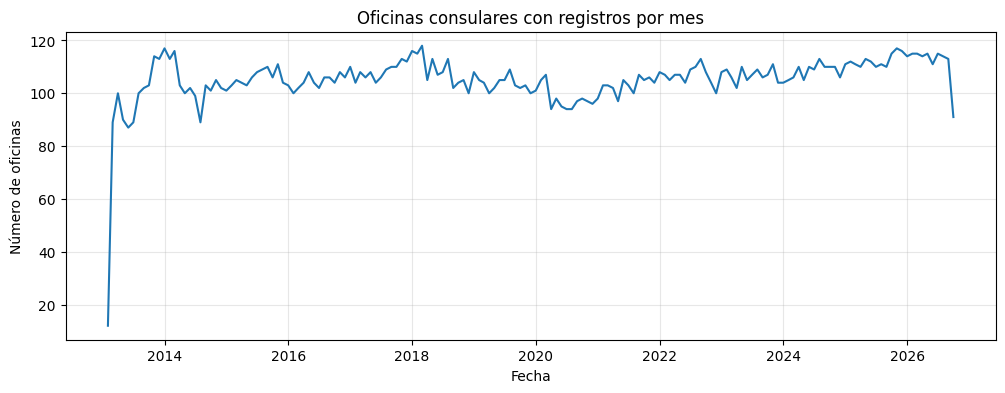

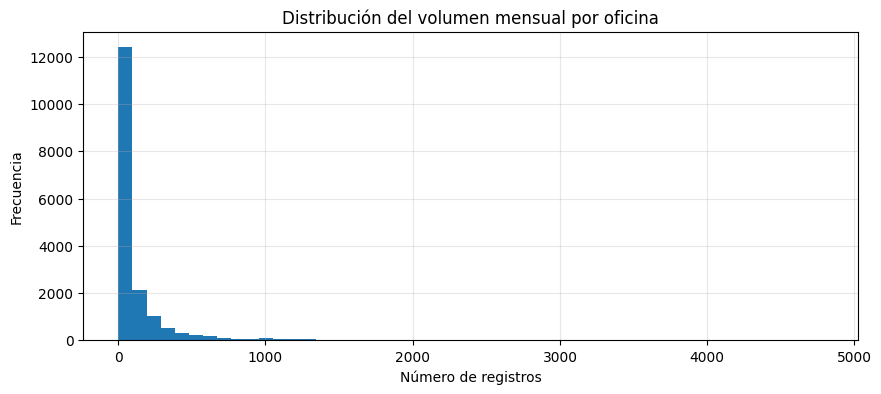


2. OFICINAS CON MAYOR VOLUMEN


,Volumen_registros
Oficina de circunscripción consular,
C. MADRID,198985
C. NUEVA YORK,100062
C. BARCELONA,97082
C. NEWARK,87412
C. VALENCIA ESP,86031
C. MIAMI,78570
C. MARACAIBO,63153
C. HOUSTON,62102
C. ORLANDO,60563



3. COBERTURA POR OFICINA


,Meses_con_registros,Meses_sin_observaciones
Oficina de circunscripción consular,,
BTA. ASISTENCIA,1,164
BTA. REFUGIO,1,164
BTA. VISAS PROTOCOLO,1,164
G.I.T. VISAS E INMIGRACION,1,164
DESCONOCIDA,1,164
VIRTUAL,5,160
C. MONTERREY,9,156
C. PUERTO PRINCIPE,10,155
C. RIO DE JANEIRO,17,148


In [10]:

# ==========================================
# ANÁLISIS DE COBERTURA Y DISTRIBUCIÓN
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Cobertura mensual de oficinas
cobertura = (
    tabla_mensual.groupby("Mes")
    ["Oficina de circunscripción consular"]
    .nunique()
)

print("1. COBERTURA TEMPORAL")
print("Mínimo de oficinas por mes:", cobertura.min())
print("Máximo de oficinas por mes:", cobertura.max())

display(cobertura.describe())

# 2. Visualizar cobertura
plt.figure(figsize=(12, 4))
plt.plot(cobertura.index.to_timestamp(), cobertura.values)
plt.title("Oficinas consulares con registros por mes")
plt.xlabel("Fecha")
plt.ylabel("Número de oficinas")
plt.grid(alpha=0.3)
plt.show()

# 3. Distribución del volumen mensual
plt.figure(figsize=(10, 4))
plt.hist(
    tabla_mensual["Volumen_registros"],
    bins=50
)
plt.title("Distribución del volumen mensual por oficina")
plt.xlabel("Número de registros")
plt.ylabel("Frecuencia")
plt.grid(alpha=0.3)
plt.show()

# 4. Oficinas con mayor volumen total
top_oficinas = (
    tabla_mensual.groupby(
        "Oficina de circunscripción consular"
    )["Volumen_registros"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\n2. OFICINAS CON MAYOR VOLUMEN")
display(top_oficinas)

# 5. Revisar meses sin observaciones por oficina
meses_totales = tabla_mensual["Mes"].nunique()

meses_por_oficina = (
    tabla_mensual.groupby(
        "Oficina de circunscripción consular"
    )["Mes"]
    .nunique()
)

resumen_oficinas = pd.DataFrame({
    "Meses_con_registros": meses_por_oficina,
    "Meses_sin_observaciones":
        meses_totales - meses_por_oficina
})

print("\n3. COBERTURA POR OFICINA")
display(
    resumen_oficinas.sort_values(
        "Meses_sin_observaciones",
        ascending=False
    ).head(15)
)


1. PRIMEROS 12 MESES


,Total_registros,Oficinas_activas
Mes,,
2013-02,478,12
2013-03,1633,89
2013-04,3472,100
2013-05,5389,90
2013-06,5241,87
2013-07,6272,89
2013-08,6325,100
2013-09,7243,102
2013-10,9626,103



2. ÚLTIMOS 12 MESES


,Total_registros,Oficinas_activas
Mes,,
2025-11,27467,117
2025-12,18419,116
2026-01,20707,114
2026-02,18233,115
2026-03,18675,115
2026-04,15373,114
2026-05,13722,115
2026-06,12387,111
2026-07,13634,115



3. CLASIFICACIÓN DE OFICINAS
Oficinas con 100 o más meses: 103
Oficinas con 60 a 99 meses: 14
Oficinas con 24 a 59 meses: 3
Oficinas con menos de 24 meses: 12

4. OFICINAS CON MENOS DE 24 MESES


,Meses observados
Oficina de circunscripción consular,
C. ESTAMBUL,21
C. SAN CARLOS DE ZULIA,21
C. GUASDUALITO,21
C. RIO DE JANEIRO,17
C. PUERTO PRINCIPE,10
C. MONTERREY,9
VIRTUAL,5
BTA. ASISTENCIA,1
BTA. VISAS PROTOCOLO,1



5. PRIMER Y ÚLTIMO MES
Primer mes: 2013-02
Último mes: 2026-10

Registros del primer mes:
Total_registros     478
Oficinas_activas     12
Name: 2013-02, dtype: int64

Registros del último mes:
Total_registros     3463
Oficinas_activas      91
Name: 2026-10, dtype: int64


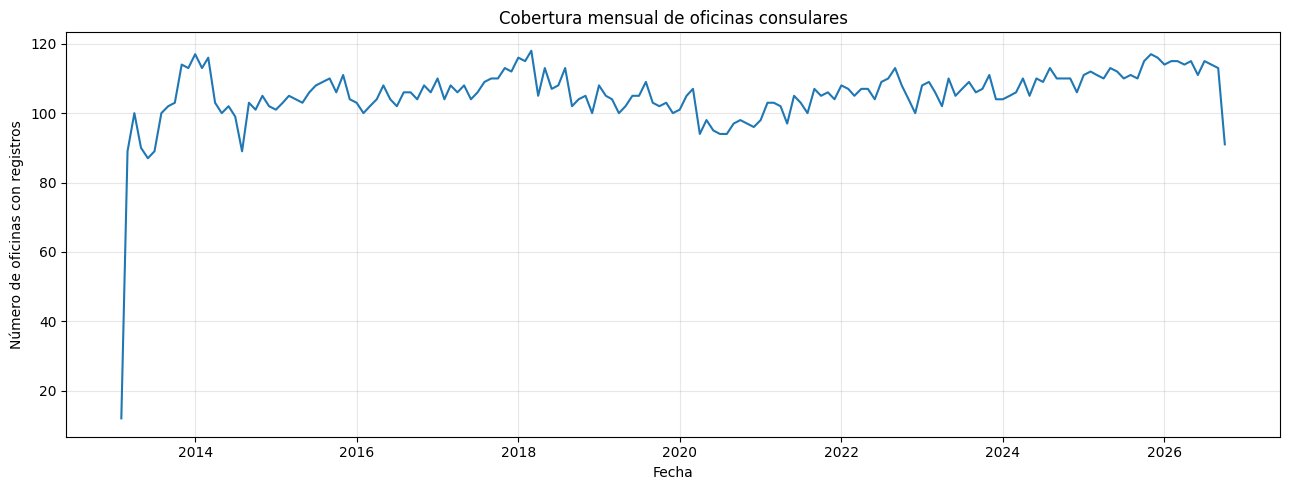

In [11]:

# ==========================================
# VALIDACIÓN DE COBERTURA Y PERIODOS
# ==========================================

# 1. Resumen mensual
resumen_mensual = (
    tabla_mensual.groupby("Mes")
    .agg(
        Total_registros=("Volumen_registros", "sum"),
        Oficinas_activas=(
            "Oficina de circunscripción consular", "nunique"
        )
    )
    .sort_index()
)

print("1. PRIMEROS 12 MESES")
display(resumen_mensual.head(12))

print("\n2. ÚLTIMOS 12 MESES")
display(resumen_mensual.tail(12))

# 2. Cobertura de cada oficina
cobertura = (
    tabla_mensual.groupby(
        "Oficina de circunscripción consular"
    )["Mes"]
    .nunique()
    .sort_values(ascending=False)
)

print("\n3. CLASIFICACIÓN DE OFICINAS")

print("Oficinas con 100 o más meses:",
      (cobertura >= 100).sum())

print("Oficinas con 60 a 99 meses:",
      ((cobertura >= 60) & (cobertura < 100)).sum())

print("Oficinas con 24 a 59 meses:",
      ((cobertura >= 24) & (cobertura < 60)).sum())

print("Oficinas con menos de 24 meses:",
      (cobertura < 24).sum())

# 3. Identificar oficinas con poco historial
print("\n4. OFICINAS CON MENOS DE 24 MESES")

display(cobertura[cobertura < 24].to_frame("Meses observados"))

# 4. Revisar periodos extremos
print("\n5. PRIMER Y ÚLTIMO MES")

print("Primer mes:", resumen_mensual.index.min())
print("Último mes:", resumen_mensual.index.max())

print("\nRegistros del primer mes:")
print(resumen_mensual.iloc[0])

print("\nRegistros del último mes:")
print(resumen_mensual.iloc[-1])

# 5. Gráfica de cobertura
plt.figure(figsize=(13, 5))

plt.plot(
    resumen_mensual.index.to_timestamp(),
    resumen_mensual["Oficinas_activas"]
)

plt.title("Cobertura mensual de oficinas consulares")
plt.xlabel("Fecha")
plt.ylabel("Número de oficinas con registros")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Octubre presenta una reducción considerable. Como el archivo fue generado en noviembre de 2026, es razonable sospechar que octubre todavía no contiene todos los registros del mes.
______

In [12]:

# ==============================================
# FASE 3: PREPARACIÓN DE LOS DATOS
# VALIDACIÓN DEL PANEL TEMPORAL
# ==============================================

import pandas as pd
import numpy as np

# 1. Crear copia del dataset mensual
datos = tabla_mensual.copy()

# 2. Convertir la variable Mes a periodo mensual
datos["Mes"] = pd.PeriodIndex(
    datos["Mes"].astype(str),
    freq="M"
)

# 3. Excluir octubre de 2026 por posible
# información incompleta
datos = datos[datos["Mes"] <= pd.Period("2026-09")].copy()

# 4. Calcular cobertura de cada oficina
cobertura_actual = (
    datos.groupby("Oficina de circunscripción consular")["Mes"]
    .nunique()
    .sort_values(ascending=False)
)

# 5. Seleccionar oficinas con mínimo 24 meses
oficinas_validas = cobertura_actual[
    cobertura_actual >= 24
].index.tolist()

datos_filtrados = datos[
    datos["Oficina de circunscripción consular"].isin(
        oficinas_validas
    )
].copy()

print("1. RESUMEN DE SELECCIÓN")
print("Oficinas originales:", datos[
    "Oficina de circunscripción consular"
].nunique())

print("Oficinas seleccionadas:", len(oficinas_validas))
print("Registros mensuales:", len(datos_filtrados))
print("Primer mes:", datos_filtrados["Mes"].min())
print("Último mes:", datos_filtrados["Mes"].max())

# 6. Construir panel de meses esperados
# desde el primer registro de cada oficina
paneles = []

ultimo_mes = datos_filtrados["Mes"].max()

for oficina, grupo in datos_filtrados.groupby(
    "Oficina de circunscripción consular"
):

    primer_mes = grupo["Mes"].min()

    meses_esperados = pd.period_range(
        start=primer_mes,
        end=ultimo_mes,
        freq="M"
    )

    panel_oficina = pd.DataFrame({
        "Mes": meses_esperados,
        "Oficina de circunscripción consular": oficina
    })

    paneles.append(panel_oficina)

panel_completo = pd.concat(
    paneles,
    ignore_index=True
)

# 7. Identificar meses con y sin observación
panel_completo = panel_completo.merge(
    datos_filtrados[
        [
            "Mes",
            "Oficina de circunscripción consular",
            "Volumen_registros"
        ]
    ],
    on=["Mes", "Oficina de circunscripción consular"],
    how="left",
    validate="one_to_one"
)

panel_completo["Estado_observacion"] = np.where(
    panel_completo["Volumen_registros"].notna(),
    "Con registro",
    "Sin observación"
)

# IMPORTANTE:
# No reemplazamos los valores faltantes por cero.

# 8. Resumen por oficina
resumen_panel = (
    panel_completo.groupby(
        "Oficina de circunscripción consular"
    )
    .agg(
        Meses_esperados=("Mes", "count"),
        Meses_observados=("Volumen_registros", "count"),
        Meses_sin_observacion=(
            "Volumen_registros",
            lambda x: x.isna().sum()
        )
    )
)

resumen_panel["Porcentaje_cobertura"] = (
    resumen_panel["Meses_observados"] /
    resumen_panel["Meses_esperados"] * 100
).round(2)

print("\n2. RESUMEN DE CONTINUIDAD TEMPORAL")
display(
    resumen_panel.sort_values(
        "Porcentaje_cobertura"
    ).head(20)
)

# 9. Resumen mensual de oficinas sin observación
resumen_ausencias = (
    panel_completo.groupby("Mes")
    .agg(
        Oficinas_esperadas=(
            "Oficina de circunscripción consular",
            "count"
        ),
        Oficinas_observadas=(
            "Volumen_registros",
            "count"
        )
    )
)

resumen_ausencias["Oficinas_sin_observacion"] = (
    resumen_ausencias["Oficinas_esperadas"] -
    resumen_ausencias["Oficinas_observadas"]
)

print("\n3. MESES CON MAYOR AUSENCIA DE INFORMACIÓN")
display(
    resumen_ausencias.sort_values(
        "Oficinas_sin_observacion",
        ascending=False
    ).head(15)
)

# 10. Resumen general
print("\n4. RESUMEN GENERAL")
print("Total de combinaciones esperadas:",
      len(panel_completo))

print("Combinaciones con registro:",
      panel_completo["Volumen_registros"].notna().sum())

print("Combinaciones sin observación:",
      panel_completo["Volumen_registros"].isna().sum())

print("Porcentaje de cobertura general:",
      round(
          panel_completo["Volumen_registros"].notna().mean() * 100,
          2
      ), "%")


1. RESUMEN DE SELECCIÓN
Oficinas originales: 132
Oficinas seleccionadas: 120
Registros mensuales: 17165
Primer mes: 2013-02
Último mes: 2026-09

2. RESUMEN DE CONTINUIDAD TEMPORAL


,Meses_esperados,Meses_observados,Meses_sin_observacion,Porcentaje_cobertura
Oficina de circunscripción consular,,,,
C. ARGEL,158,35,123,22.15
C. BAKÚ,153,52,101,33.99
C. PUERTO OBALDIA,162,65,97,40.12
C. JAQUE,142,59,83,41.55
C. SAN FNDO ATABAPO,161,68,93,42.24
C. NUEVA DELHI,157,69,88,43.95
C. MACHIQUES,163,76,87,46.63
C. KINGSTON,163,77,86,47.24
C. JAKARTA,163,77,86,47.24



3. MESES CON MAYOR AUSENCIA DE INFORMACIÓN


,Oficinas_esperadas,Oficinas_observadas,Oficinas_sin_observacion
Mes,,,
2014-08,119,89,30
2020-04,120,93,27
2020-07,120,94,26
2020-06,120,94,26
2020-08,120,94,26
2020-05,120,96,24
2020-12,120,96,24
2020-11,120,97,23
2020-09,120,97,23



4. RESUMEN GENERAL
Total de combinaciones esperadas: 19471
Combinaciones con registro: 17165
Combinaciones sin observación: 2306
Porcentaje de cobertura general: 88.16 %


In [13]:

# ============================================
# EVALUACIÓN DE COBERTURA POR OFICINA
# ============================================

# 1. Cobertura histórica
cobertura = resumen_panel.copy()

# 2. Evaluar los últimos 24 meses
ultimo_mes = datos_filtrados["Mes"].max()

meses_recientes = pd.period_range(
    end=ultimo_mes,
    periods=24,
    freq="M"
)

datos_recientes = panel_completo[
    panel_completo["Mes"].isin(meses_recientes)
]

cobertura_reciente = (
    datos_recientes.groupby(
        "Oficina de circunscripción consular"
    )["Volumen_registros"]
    .apply(lambda x: x.notna().sum() / 24 * 100)
)

cobertura["Cobertura_ultimos_24_meses"] = (
    cobertura_reciente
)

# 3. Clasificar las oficinas según cobertura histórica
def clasificar_cobertura(valor):
    if valor >= 95:
        return "Excelente"
    elif valor >= 80:
        return "Buena"
    elif valor >= 60:
        return "Moderada"
    else:
        return "Baja"

cobertura["Clasificacion"] = (
    cobertura["Porcentaje_cobertura"]
    .apply(clasificar_cobertura)
)

# 4. Resumen de cobertura histórica
print("1. CLASIFICACIÓN DE COBERTURA HISTÓRICA")

print(
    cobertura["Clasificacion"]
    .value_counts()
)

# 5. Evaluar diferentes umbrales
print("\n2. OFICINAS SEGÚN UMBRAL DE COBERTURA")

for porcentaje in [60, 70, 80, 90, 95, 100]:

    cantidad = (
        cobertura["Porcentaje_cobertura"] >= porcentaje
    ).sum()

    print(
        f"Oficinas con cobertura >= {porcentaje}%: "
        f"{cantidad}"
    )

# 6. Evaluar cobertura reciente
print("\n3. COBERTURA DE LOS ÚLTIMOS 24 MESES")

for porcentaje in [50, 70, 80, 90, 95, 100]:

    cantidad = (
        cobertura["Cobertura_ultimos_24_meses"] >= porcentaje
    ).sum()

    print(
        f"Oficinas con cobertura reciente >= {porcentaje}%: "
        f"{cantidad}"
    )

# 7. Mostrar las oficinas con menor cobertura reciente
print("\n4. OFICINAS CON MENOR COBERTURA RECIENTE")

display(
    cobertura.sort_values(
        "Cobertura_ultimos_24_meses"
    )[
        [
            "Meses_esperados",
            "Meses_observados",
            "Porcentaje_cobertura",
            "Cobertura_ultimos_24_meses"
        ]
    ].head(20)
)

# 8. Mostrar las oficinas con mejor cobertura
print("\n5. OFICINAS CON MEJOR COBERTURA")

display(
    cobertura.sort_values(
        "Porcentaje_cobertura",
        ascending=False
    ).head(15)
)


1. CLASIFICACIÓN DE COBERTURA HISTÓRICA
Clasificacion
Excelente    79
Baja         17
Buena        13
Moderada     11
Name: count, dtype: int64

2. OFICINAS SEGÚN UMBRAL DE COBERTURA
Oficinas con cobertura >= 60%: 103
Oficinas con cobertura >= 70%: 97
Oficinas con cobertura >= 80%: 92
Oficinas con cobertura >= 90%: 81
Oficinas con cobertura >= 95%: 79
Oficinas con cobertura >= 100%: 47

3. COBERTURA DE LOS ÚLTIMOS 24 MESES
Oficinas con cobertura reciente >= 50%: 112
Oficinas con cobertura reciente >= 70%: 106
Oficinas con cobertura reciente >= 80%: 101
Oficinas con cobertura reciente >= 90%: 96
Oficinas con cobertura reciente >= 95%: 95
Oficinas con cobertura reciente >= 100%: 89

4. OFICINAS CON MENOR COBERTURA RECIENTE


,Meses_esperados,Meses_observados,Porcentaje_cobertura,Cobertura_ultimos_24_meses
Oficina de circunscripción consular,,,,
C. SAN FNDO ATABAPO,161,68,42.24,20.833333
C. NUEVA DELHI,157,69,43.95,25.000000
C. ARGEL,158,35,22.15,29.166667
C. HANOI,156,85,54.49,33.333333
C. JAKARTA,163,77,47.24,41.666667
C. BAKÚ,153,52,33.99,41.666667
C. KINGSTON,163,77,47.24,45.833333
C. EL AMPARO,162,102,62.96,45.833333
C. KUALA LUMPUR,163,95,58.28,50.000000



5. OFICINAS CON MEJOR COBERTURA


,Meses_esperados,Meses_observados,Meses_sin_observacion,Porcentaje_cobertura,Cobertura_ultimos_24_meses,Clasificacion
Oficina de circunscripción consular,,,,,,
C. ABU DHABI,163,163,0,100.0,100.0,Excelente
C. AMSTERDAM,163,163,0,100.0,100.0,Excelente
C. ANTOFAGASTA,163,163,0,100.0,100.0,Excelente
C. BOSTON,163,163,0,100.0,100.0,Excelente
C. BRUSELAS,163,163,0,100.0,100.0,Excelente
C. BERNA,163,163,0,100.0,100.0,Excelente
C. BARCELONA,163,163,0,100.0,100.0,Excelente
C. ATLANTA,164,164,0,100.0,100.0,Excelente
C. BERLIN,163,163,0,100.0,100.0,Excelente


In [14]:

# ============================================
# SELECCIÓN DEFINITIVA DE OFICINAS CONSULARES
# ============================================

# Criterios de selección
criterio_historico = (
    cobertura["Porcentaje_cobertura"] >= 80
)

criterio_reciente = (
    cobertura["Cobertura_ultimos_24_meses"] >= 80
)

# Seleccionar oficinas que cumplen ambos criterios
oficinas_seleccionadas = cobertura[
    criterio_historico & criterio_reciente
].index.tolist()

# Resumen de selección
print("1. RESULTADO DE LA SELECCIÓN")
print("----------------------------------")
print("Oficinas evaluadas:", len(cobertura))
print("Oficinas seleccionadas:", len(oficinas_seleccionadas))
print("Oficinas excluidas:", len(cobertura) - len(oficinas_seleccionadas))

# Crear nuevo panel con las oficinas seleccionadas
panel_modelo = panel_completo[
    panel_completo[
        "Oficina de circunscripción consular"
    ].isin(oficinas_seleccionadas)
].copy()

# Ordenar información
panel_modelo = panel_modelo.sort_values(
    ["Oficina de circunscripción consular", "Mes"]
)

# Revisar información faltante
print("\n2. CALIDAD DEL PANEL SELECCIONADO")
print("----------------------------------")
print("Total de observaciones:", len(panel_modelo))
print(
    "Valores faltantes:",
    panel_modelo["Volumen_registros"].isna().sum()
)

print(
    "Oficinas seleccionadas:",
    panel_modelo[
        "Oficina de circunscripción consular"
    ].nunique()
)

# Mostrar oficinas seleccionadas
print("\n3. OFICINAS INCLUIDAS")
display(
    cobertura.loc[oficinas_seleccionadas][
        [
            "Meses_observados",
            "Porcentaje_cobertura",
            "Cobertura_ultimos_24_meses"
        ]
    ].sort_values(
        "Porcentaje_cobertura",
        ascending=False
    )
)

# Guardar el panel seleccionado
panel_modelo.to_csv(
    "panel_modelo_oficinas.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nPanel de modelamiento guardado correctamente.")


1. RESULTADO DE LA SELECCIÓN
----------------------------------
Oficinas evaluadas: 120
Oficinas seleccionadas: 91
Oficinas excluidas: 29

2. CALIDAD DEL PANEL SELECCIONADO
----------------------------------
Total de observaciones: 14828
Valores faltantes: 344
Oficinas seleccionadas: 91

3. OFICINAS INCLUIDAS


,Meses_observados,Porcentaje_cobertura,Cobertura_ultimos_24_meses
Oficina de circunscripción consular,,,
C. ABU DHABI,163,100.00,100.000000
C. AMSTERDAM,163,100.00,100.000000
C. ANTOFAGASTA,163,100.00,100.000000
C. ATLANTA,164,100.00,100.000000
C. BARCELONA,163,100.00,100.000000
...,...,...,...
C. SEUL,139,85.80,95.833333
C. SINGAPUR,136,83.95,87.500000
C. DUBLIN,135,83.33,100.000000



Panel de modelamiento guardado correctamente.


In [15]:

# ============================================
# ANALISIS DE VALORES FALTANTES
# ============================================

# Identificar registros sin volumen
faltantes = panel_modelo[
    panel_modelo["Volumen_registros"].isna()
].copy()

print("1. RESUMEN DE VALORES FALTANTES")
print("--------------------------------")
print("Total de valores faltantes:", len(faltantes))
print("Oficinas afectadas:",
      faltantes["Oficina de circunscripción consular"].nunique())
print("Meses afectados:", faltantes["Mes"].nunique())

# Revisar ejemplos
print("\n2. PRIMEROS REGISTROS FALTANTES")
display(faltantes.head(15))

# Cantidad de faltantes por oficina
print("\n3. FALTANTES POR OFICINA")
faltantes_oficina = (
    faltantes.groupby("Oficina de circunscripción consular")
    .size()
    .sort_values(ascending=False)
)

display(faltantes_oficina.head(20))

# Cantidad de faltantes por mes
print("\n4. FALTANTES POR MES")
faltantes_mes = (
    faltantes.groupby("Mes")
    .size()
    .sort_values(ascending=False)
)

display(faltantes_mes.head(20))


1. RESUMEN DE VALORES FALTANTES
--------------------------------
Total de valores faltantes: 344
Oficinas afectadas: 44
Meses afectados: 125

2. PRIMEROS REGISTROS FALTANTES


,Mes,Oficina de circunscripción consular,Volumen_registros,Estado_observacion
969,2013-04,C. ARUBA,NaN,Sin observación
1053,2020-04,C. ARUBA,NaN,Sin observación
1462,2013-08,C. AUCKLAND,NaN,Sin observación
1774,2013-05,C. BANGKOK,NaN,Sin observación
1776,2013-07,C. BANGKOK,NaN,Sin observación
1777,2013-08,C. BANGKOK,NaN,Sin observación
1795,2015-02,C. BANGKOK,NaN,Sin observación
1798,2015-05,C. BANGKOK,NaN,Sin observación
1801,2015-08,C. BANGKOK,NaN,Sin observación
1808,2016-03,C. BANGKOK,NaN,Sin observación



3. FALTANTES POR OFICINA


,0
Oficina de circunscripción consular,
C. BANGKOK,29
C. EL CAIRO,28
C. DUBLIN,27
C. SINGAPUR,26
C. HELSINKI,23
C. SEUL,23
C. BEIRUT,20
C. CANCUN,19
C. PUERTO AYACUCHO,19



4. FALTANTES POR MES


,0
Mes,
2014-08,12
2013-06,11
2020-05,11
2020-04,11
2020-06,10
2013-07,9
2020-07,8
2020-08,8
2013-08,7


Indicador	Resultado

Valores faltantes	344

Oficinas afectadas	44

Meses afectados	125

Registros del panel	14.828

Los 344 registros aparecen identificados como «Sin observación».
______
Debido a que la ausencia de información no demuestra que el volumen de registros haya sido cero, se decidió conservar estos valores como datos faltantes y no realizar una imputación arbitraria. Para el entrenamiento de los modelos se utilizarán únicamente observaciones con valores reales disponibles en la variable objetivo, respetando el orden cronológico de los datos.

#-Construcción de variables predictoras
preparar el conjunto de datos para los modelos de regresión.

Información histórica para estimar el volumen mensual de cada oficina.

Las variables serán:
Variable	Utilidad
Año	Identificar la tendencia temporal
Mes	Identificar comportamientos estacionales
Mes seno y coseno	Representar ciclos anuales
Rezago 1	Volumen del mes anterior
Rezago 2	Volumen de hace dos meses
Rezago 3	Volumen de hace tres meses
Rezago 6	Volumen de hace seis meses
Rezago 12	Volumen del mismo periodo del año anterior
Promedio móvil 3	Comportamiento reciente
Promedio móvil 6	Comportamiento de los últimos seis meses

In [16]:

import pandas as pd
import numpy as np

# ============================================
# 1. COPIAR Y ORGANIZAR EL PANEL
# ============================================

datos = panel_modelo.copy()

col_oficina = "Oficina de circunscripción consular"
objetivo = "Volumen_registros"

datos["Mes_periodo"] = pd.PeriodIndex(
    datos["Mes"].astype(str), freq="M"
)

datos[objetivo] = pd.to_numeric(
    datos[objetivo], errors="coerce"
)

# Verificar registros duplicados
duplicados = datos.duplicated(
    subset=[col_oficina, "Mes_periodo"]
).sum()

print("Registros duplicados:", duplicados)

if duplicados > 0:
    raise ValueError(
        "Existen oficinas con meses duplicados. "
        "Debemos revisarlos antes de continuar."
    )

# ============================================
# 2. COMPLETAR EL CALENDARIO MENSUAL
# ============================================

# Se completan posibles meses ausentes dentro
# del periodo registrado de cada oficina.
paneles = []

for oficina, grupo in datos.groupby(col_oficina):

    grupo = grupo.set_index("Mes_periodo").sort_index()

    calendario = pd.period_range(
        grupo.index.min(),
        grupo.index.max(),
        freq="M"
    )

    grupo = grupo.reindex(calendario)

    grupo[col_oficina] = oficina

    if "Estado_observacion" in grupo.columns:
        grupo["Estado_observacion"] = (
            grupo["Estado_observacion"]
            .fillna("Sin observación")
        )

    paneles.append(grupo)

datos = pd.concat(paneles).reset_index()

datos = datos.rename(
    columns={"index": "Mes_periodo"}
)

datos["Mes"] = datos["Mes_periodo"].astype(str)

datos = datos.sort_values(
    [col_oficina, "Mes_periodo"]
).reset_index(drop=True)

# ============================================
# 3. CREAR VARIABLES TEMPORALES
# ============================================

datos["Año"] = datos["Mes_periodo"].dt.year
datos["Numero_mes"] = datos["Mes_periodo"].dt.month
datos["Trimestre"] = datos["Mes_periodo"].dt.quarter

datos["Mes_seno"] = np.sin(
    2 * np.pi * datos["Numero_mes"] / 12
)

datos["Mes_coseno"] = np.cos(
    2 * np.pi * datos["Numero_mes"] / 12
)

# ============================================
# 4. CREAR REZAGOS POR OFICINA
# ============================================

grupo = datos.groupby(col_oficina)[objetivo]

for periodo in [1, 2, 3, 6, 12]:

    datos[f"Rezago_{periodo}"] = (
        grupo.shift(periodo)
    )

# ============================================
# 5. CREAR PROMEDIOS MOVILES
# ============================================

for ventana in [3, 6]:

    datos[f"Promedio_movil_{ventana}"] = (
        datos.groupby(col_oficina)[objetivo]
        .transform(
            lambda serie: serie.shift(1).rolling(
                window=ventana,
                min_periods=ventana
            ).mean()
        )
    )

# ============================================
# 6. CREAR CONJUNTO PARA MODELAMIENTO
# ============================================

variables_predictoras = [
    "Año",
    "Numero_mes",
    "Trimestre",
    "Mes_seno",
    "Mes_coseno",
    "Rezago_1",
    "Rezago_2",
    "Rezago_3",
    "Rezago_6",
    "Rezago_12",
    "Promedio_movil_3",
    "Promedio_movil_6"
]

columnas_modelo = [
    col_oficina,
    "Mes",
    objetivo
] + variables_predictoras

# Se conservan solo filas con objetivo y
# todas las variables predictoras disponibles.
modelo_regresion = datos[columnas_modelo].dropna(
    subset=[objetivo] + variables_predictoras
).copy()

print("====================================")
print("RESULTADO DE PREPARACIÓN TEMPORAL")
print("====================================")

print("Oficinas:", datos[col_oficina].nunique())
print("Observaciones del panel:", len(datos))
print("Registros con objetivo disponible:",
      datos[objetivo].notna().sum())
print("Registros preparados para modelamiento:",
      len(modelo_regresion))
print("Variables predictoras:",
      len(variables_predictoras))

print("\nPrimeros registros:")
display(modelo_regresion.head())

# Guardar archivos
datos.to_csv(
    "panel_con_variables_temporales.csv",
    index=False,
    encoding="utf-8-sig"
)

modelo_regresion.to_csv(
    "datos_modelamiento_regresion.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivos guardados correctamente.")


Registros duplicados: 0
RESULTADO DE PREPARACIÓN TEMPORAL
Oficinas: 91
Observaciones del panel: 14828
Registros con objetivo disponible: 14484
Registros preparados para modelamiento: 12478
Variables predictoras: 12

Primeros registros:


,Oficina de circunscripción consular,Mes,Volumen_registros,Año,Numero_mes,Trimestre,Mes_seno,Mes_coseno,Rezago_1,Rezago_2,Rezago_3,Rezago_6,Rezago_12,Promedio_movil_3,Promedio_movil_6
12,C. ABU DHABI,2014-03,132.0,2014,3,1,1.000000e+00,6.123234e-17,53.0,159.0,163.0,26.0,9.0,125.000000,70.166667
13,C. ABU DHABI,2014-04,5.0,2014,4,2,8.660254e-01,-5.000000e-01,132.0,53.0,159.0,4.0,8.0,114.666667,87.833333
14,C. ABU DHABI,2014-05,8.0,2014,5,2,5.000000e-01,-8.660254e-01,5.0,132.0,53.0,16.0,5.0,63.333333,88.000000
15,C. ABU DHABI,2014-06,6.0,2014,6,2,1.224647e-16,-1.000000e+00,8.0,5.0,132.0,163.0,7.0,48.333333,86.666667
16,C. ABU DHABI,2014-07,6.0,2014,7,3,-5.000000e-01,-8.660254e-01,6.0,8.0,5.0,159.0,2.0,6.333333,60.500000



Archivos guardados correctamente.


In [17]:

# ============================================
# 1. DIVISIÓN TEMPORAL DEL DATASET
# ============================================

# Variable objetivo
objetivo = "Volumen_registros"

# Identificación de oficina
col_oficina = "Oficina de circunscripción consular"

# Variables predictoras
variables_predictoras = [
    "Año",
    "Numero_mes",
    "Trimestre",
    "Mes_seno",
    "Mes_coseno",
    "Rezago_1",
    "Rezago_2",
    "Rezago_3",
    "Rezago_6",
    "Rezago_12",
    "Promedio_movil_3",
    "Promedio_movil_6"
]

# Ordenar los meses cronológicamente
meses = sorted(modelo_regresion["Mes"].unique())

# Establecer corte temporal 80/20
punto_corte = int(len(meses) * 0.80)
mes_corte = meses[punto_corte]

# Separar entrenamiento y prueba
train = modelo_regresion[
    modelo_regresion["Mes"] < mes_corte
].copy()

test = modelo_regresion[
    modelo_regresion["Mes"] >= mes_corte
].copy()

# Construir matrices predictoras
X_train = train[variables_predictoras + [col_oficina]]
X_test = test[variables_predictoras + [col_oficina]]

# Definir variable objetivo
y_train = train[objetivo]
y_test = test[objetivo]

# ============================================
# 2. VALIDACIÓN DE LA DIVISIÓN
# ============================================

print("RESULTADO DE LA DIVISIÓN TEMPORAL")
print("=" * 45)

print("\nFECHA DE CORTE:", mes_corte)

print("\nENTRENAMIENTO")
print("Registros:", len(X_train))
print("Mes inicial:", train["Mes"].min())
print("Mes final:", train["Mes"].max())

print("\nPRUEBA")
print("Registros:", len(X_test))
print("Mes inicial:", test["Mes"].min())
print("Mes final:", test["Mes"].max())

print("\nVALIDACIÓN")
print("Oficinas entrenamiento:", X_train[col_oficina].nunique())
print("Oficinas prueba:", X_test[col_oficina].nunique())

print("\nTotal de registros:", len(train) + len(test))
print("Variables predictoras:", X_train.shape[1])

print("\n¿Existen valores nulos?")
print("Entrenamiento:", X_train.isnull().sum().sum())
print("Prueba:", X_test.isnull().sum().sum())


RESULTADO DE LA DIVISIÓN TEMPORAL

FECHA DE CORTE: 2024-03

ENTRENAMIENTO
Registros: 9775
Mes inicial: 2014-02
Mes final: 2024-02

PRUEBA
Registros: 2703
Mes inicial: 2024-03
Mes final: 2026-09

VALIDACIÓN
Oficinas entrenamiento: 91
Oficinas prueba: 91

Total de registros: 12478
Variables predictoras: 13

¿Existen valores nulos?
Entrenamiento: 0
Prueba: 0


1. Las 91 oficinas están presentes en ambos conjuntos.
2. No existen valores nulos en las variables predictoras.
3. Se respetó el orden cronológico: el modelo entrenará con información anterior y se evaluará con información posterior.
4. La distribución quedó aproximadamente en 78,3 % para entrenamiento y 21,7 % para prueba. Es normal que no sea exactamente 80/20 porque estamos separando meses completos.

#1. Análisis de los resultados

Indicador	                Resultado

Total de registros	         12.478

Entrenamiento	                9.775

Prueba	                      2.703

Oficinas incluidas	             91

Variables predictoras	           13

Valores nulos en entrenamiento	  0

Valores nulos en prueba	          0

Periodo de entrenamiento: febrero de 2014 a febrero de 2024.

Periodo de prueba: marzo de 2024 a septiembre de 2026.


#2. Entrenamiento y comparación de modelos
Ahora vamos a comparar cuatro algoritmos:
- Regresión lineal: modelo de referencia.
- Ridge: regresión con regularización.
- Random Forest: identifica relaciones no lineales.
- HistGradientBoosting: identifica patrones complejos y tendencias.

In [18]:

# ============================================
# 1. IMPORTAR LIBRERIAS
# ============================================

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ============================================
# 2. DEFINIR VARIABLES
# ============================================

objetivo = "Volumen_registros"

col_oficina = "Oficina de circunscripción consular"

variables_numericas = [
    "Año",
    "Numero_mes",
    "Trimestre",
    "Mes_seno",
    "Mes_coseno",
    "Rezago_1",
    "Rezago_2",
    "Rezago_3",
    "Rezago_6",
    "Rezago_12",
    "Promedio_movil_3",
    "Promedio_movil_6"
]

variables_categoricas = [col_oficina]

# ============================================
# 3. PREPROCESAMIENTO
# ============================================

# Compatibilidad con distintas versiones
# de Scikit-learn

try:
    codificador = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    codificador = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

preprocesamiento = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), variables_numericas),
        ("categoricas", codificador, variables_categoricas)
    ]
)

# ============================================
# 4. DEFINIR MODELOS
# ============================================

modelos = {
    "Regresión Lineal": LinearRegression(),

    "Ridge": Ridge(alpha=1.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=250,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=31,
        random_state=42
    )
}

# ============================================
# 5. ENTRENAMIENTO Y EVALUACION
# ============================================

resultados = []
modelos_entrenados = {}
predicciones = {}

for nombre, algoritmo in modelos.items():

    pipeline = Pipeline(steps=[
        ("preprocesamiento", preprocesamiento),
        ("modelo", algoritmo)
    ])

    # Entrenar
    pipeline.fit(X_train, y_train)

    # Predecir
    pred = pipeline.predict(X_test)

    # Evaluar
    mae = mean_absolute_error(y_test, pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, pred)
    )

    r2 = r2_score(y_test, pred)

    resultados.append({
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    modelos_entrenados[nombre] = pipeline
    predicciones[nombre] = pred

# ============================================
# 6. MODELO BASELINE
# ============================================

pred_baseline = test["Rezago_1"]

resultados.append({
    "Modelo": "Baseline (Rezago 1)",
    "MAE": mean_absolute_error(y_test, pred_baseline),
    "RMSE": np.sqrt(
        mean_squared_error(y_test, pred_baseline)
    ),
    "R2": r2_score(y_test, pred_baseline)
})

# ============================================
# 7. TABLA COMPARATIVA
# ============================================

tabla_resultados = pd.DataFrame(resultados)

tabla_resultados = tabla_resultados.sort_values(
    by="RMSE"
).reset_index(drop=True)

print("============================================")
print("COMPARACIÓN DE MODELOS DE REGRESIÓN")
print("============================================")

display(
    tabla_resultados.round(4)
)

print("\nMEJOR MODELO SEGÚN RMSE:")
print(tabla_resultados.iloc[0]["Modelo"])


COMPARACIÓN DE MODELOS DE REGRESIÓN


,Modelo,MAE,RMSE,R2
0,Ridge,44.5648,85.2521,0.9299
1,Regresión Lineal,44.6044,85.2881,0.9299
2,Random Forest,42.9775,91.7832,0.9188
3,Baseline (Rezago 1),43.1672,93.6656,0.9154
4,HistGradientBoosting,45.2837,99.2034,0.9051



MEJOR MODELO SEGÚN RMSE:
Ridge


#Ridge
- Tiene el menor RMSE.
- Explica aproximadamente el 92,99 % de la variabilidad observada.
- Es el mejor candidato cuando queremos penalizar especialmente los errores grandes.

#Random Forest
- Tiene el menor MAE: 42,98 registros.
- Su error absoluto promedio es ligeramente inferior al del modelo de referencia.
- Puede ser interesante cuando buscamos reducir el error promedio.

#Regresión lineal
- Presenta resultados prácticamente iguales a Ridge.
- Esto indica que la regularización aplicada con alpha = 1 produce una diferencia muy pequeña.

Ridge reduce el RMSE aproximadamente un 8,97% frente al modelo de referencia.
Sin embargo, todavía no debemos declararlo ganador definitivo. Necesitamos estudiar los errores por oficina consular y comprobar que no existan sesgos importantes.

COMPARACION DE ERRORES
MAE Ridge: 44.56
MAE Random Forest: 42.98

10 OFICINAS CON MAYOR ERROR DE RIDGE


,Oficina de circunscripción consular,Registros,MAE_Ridge,MAE_RandomForest,Sesgo_Ridge,Sesgo_RF
41,C. MADRID,31,250.68,335.69,-52.05,-323.37
7,C. BARCELONA,31,205.88,179.75,-64.33,-62.45
84,C. VALENCIA ESP,31,184.47,167.59,-62.71,-5.38
53,C. NUEVA YORK,31,118.96,124.49,8.75,57.50
51,C. NEWARK,31,118.08,123.02,-3.63,66.37
33,C. HOUSTON,31,116.35,136.66,-22.91,41.44
75,C. SEVILLA,31,116.03,116.56,-39.10,10.71
13,C. BILBAO,31,111.19,127.47,-33.69,42.04
22,C. CHICAGO,31,108.91,113.33,-17.59,46.36
40,C. LOS ANGELES,31,102.21,123.34,12.62,71.09



ULTIMOS 12 MESES EVALUADOS


,MAE_Ridge,MAE_RandomForest
Mes,,
2025-10,50.48,39.92
2025-11,104.47,108.36
2025-12,64.51,38.84
2026-01,40.64,44.62
2026-02,52.00,61.42
2026-03,37.11,63.74
2026-04,45.38,60.50
2026-05,34.91,41.36
2026-06,43.22,46.05


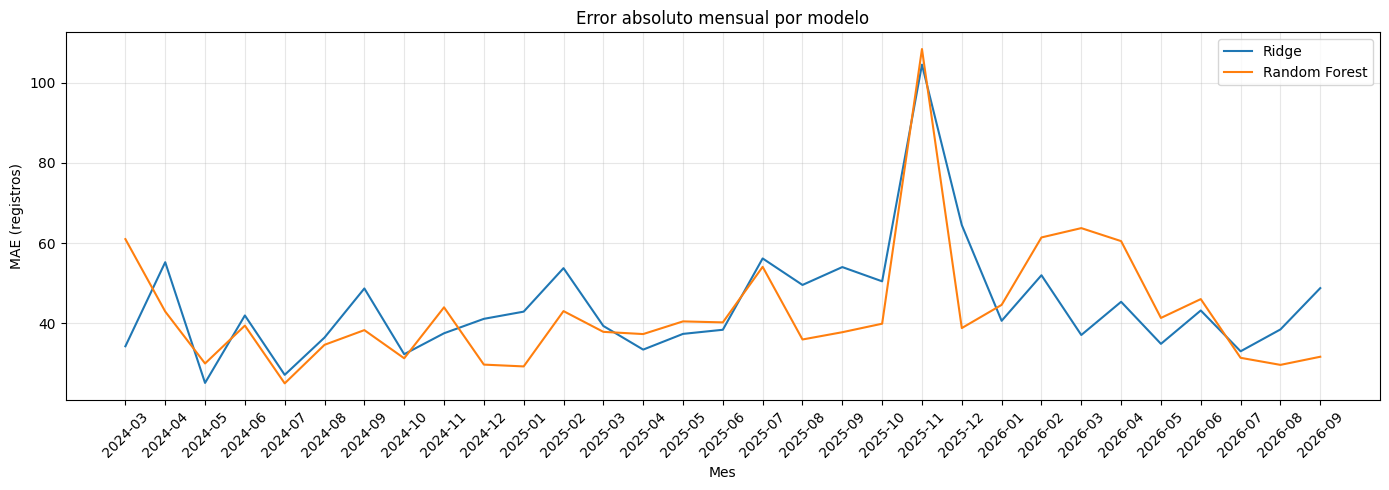

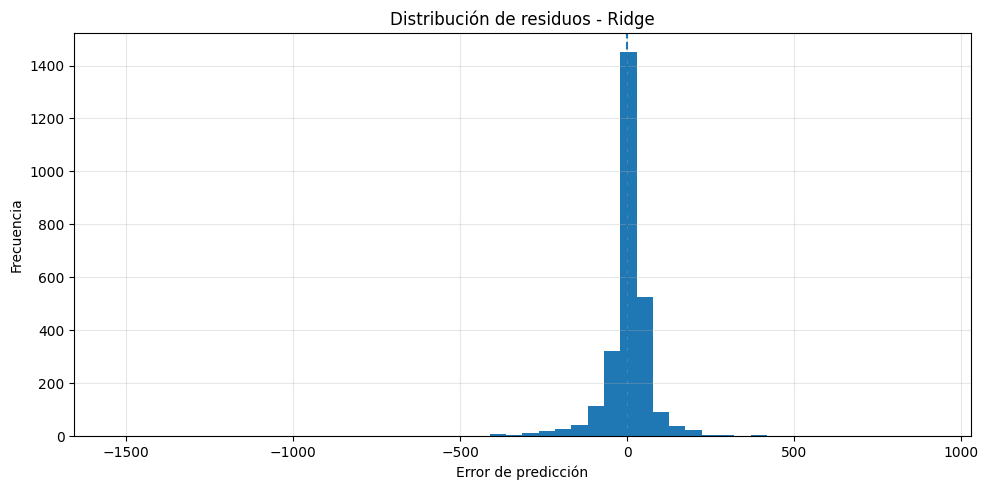

In [19]:

# ============================================
# ANALISIS DE ERRORES POR OFICINA
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Construir tabla de predicciones
analisis = test[
    ["Mes", col_oficina]
].copy().reset_index(drop=True)

analisis["Real"] = y_test.reset_index(drop=True)

analisis["Pred_Ridge"] = predicciones["Ridge"]
analisis["Pred_RandomForest"] = predicciones["Random Forest"]

analisis["Error_Ridge"] = (
    analisis["Pred_Ridge"] - analisis["Real"]
)

analisis["Error_RF"] = (
    analisis["Pred_RandomForest"] - analisis["Real"]
)

analisis["ErrorAbs_Ridge"] = analisis["Error_Ridge"].abs()
analisis["ErrorAbs_RF"] = analisis["Error_RF"].abs()

# ============================================
# 1. RESULTADOS GENERALES
# ============================================

print("COMPARACION DE ERRORES")
print("=" * 45)

print("MAE Ridge:",
      round(analisis["ErrorAbs_Ridge"].mean(), 2))

print("MAE Random Forest:",
      round(analisis["ErrorAbs_RF"].mean(), 2))

# ============================================
# 2. ERROR POR OFICINA
# ============================================

errores_oficina = analisis.groupby(
    col_oficina
).agg(
    Registros=("Real", "count"),
    MAE_Ridge=("ErrorAbs_Ridge", "mean"),
    MAE_RandomForest=("ErrorAbs_RF", "mean"),
    Sesgo_Ridge=("Error_Ridge", "mean"),
    Sesgo_RF=("Error_RF", "mean")
).reset_index()

errores_oficina = errores_oficina.sort_values(
    "MAE_Ridge", ascending=False
)

print("\n10 OFICINAS CON MAYOR ERROR DE RIDGE")
display(errores_oficina.head(10).round(2))

# ============================================
# 3. ERROR MENSUAL
# ============================================

error_mensual = analisis.groupby("Mes").agg(
    MAE_Ridge=("ErrorAbs_Ridge", "mean"),
    MAE_RandomForest=("ErrorAbs_RF", "mean")
)

print("\nULTIMOS 12 MESES EVALUADOS")
display(error_mensual.tail(12).round(2))

# ============================================
# 4. GRAFICO DE COMPARACION
# ============================================

plt.figure(figsize=(14, 5))

plt.plot(
    error_mensual.index,
    error_mensual["MAE_Ridge"],
    label="Ridge"
)

plt.plot(
    error_mensual.index,
    error_mensual["MAE_RandomForest"],
    label="Random Forest"
)

plt.title("Error absoluto mensual por modelo")
plt.xlabel("Mes")
plt.ylabel("MAE (registros)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================
# 5. DISTRIBUCION DE RESIDUOS
# ============================================

plt.figure(figsize=(10, 5))

plt.hist(
    analisis["Error_Ridge"],
    bins=50
)

plt.axvline(0, linestyle="--")

plt.title("Distribución de residuos - Ridge")
plt.xlabel("Error de predicción")
plt.ylabel("Frecuencia")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#Análisis de errores por oficina
Hay tres hallazgos:
- Madrid presenta el mayor error en ambos modelos.
- Barcelona y Valencia también presentan dificultades importantes.
- Random Forest mejora el error en Barcelona y Valencia, pero empeora considerablemente en Madrid.
____
#Comportamiento temporal
En noviembre de 2025 se observa un incremento considerable del error:
- Ridge: 104,47 registros.
- Random Forest: 108,36 registros.
También encontramos que:
- Ridge funciona mejor entre marzo y junio de 2026.
- Random Forest obtiene mejores resultados en agosto y septiembre de 2026.
- En julio de 2026 ambos modelos presentan errores relativamente bajos.
Esto indica que el desempeño cambia según el periodo evaluado.
____
#Distribución de residuos
El histograma de Ridge muestra una concentración importante de errores alrededor de cero, pero también presenta una cola larga hacia los valores negativos.

Esto significa que existen algunas predicciones con errores considerablemente grandes.

Error = Predicción - Valor\ real


Por tanto:
- Error negativo: el modelo subestima.
- Error positivo: el modelo sobreestima.

In [20]:

# ============================================
# DIAGNOSTICO DE VALORES EXTREMOS
# ============================================

# 1. Estadisticas de errores absolutos

print("DISTRIBUCION DE ERRORES ABSOLUTOS")
print("=" * 50)

for nombre, columna in [
    ("Ridge", "ErrorAbs_Ridge"),
    ("Random Forest", "ErrorAbs_RF")
]:
    print(f"\n{nombre}")
    print(analisis[columna].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2))

# 2. Mayores errores individuales de Ridge

print("\n20 MAYORES ERRORES DE RIDGE")

peores_ridge = analisis.nlargest(
    20, "ErrorAbs_Ridge"
)[[
    "Mes",
    col_oficina,
    "Real",
    "Pred_Ridge",
    "Error_Ridge",
    "ErrorAbs_Ridge"
]]

display(peores_ridge.round(2))

# 3. Mayores errores individuales de Random Forest

print("\n20 MAYORES ERRORES DE RANDOM FOREST")

peores_rf = analisis.nlargest(
    20, "ErrorAbs_RF"
)[[
    "Mes",
    col_oficina,
    "Real",
    "Pred_RandomForest",
    "Error_RF",
    "ErrorAbs_RF"
]]

display(peores_rf.round(2))

# 4. Revisar noviembre de 2025

print("\nANALISIS DE NOVIEMBRE DE 2025")

noviembre = analisis[
    analisis["Mes"] == "2025-11"
].copy()

display(
    noviembre.sort_values(
        "ErrorAbs_Ridge",
        ascending=False
    )[[
        "Mes",
        col_oficina,
        "Real",
        "Pred_Ridge",
        "ErrorAbs_Ridge",
        "Pred_RandomForest",
        "ErrorAbs_RF"
    ]].head(15).round(2)
)

# 5. Revisar predicciones negativas

print("\nPREDICCIONES NEGATIVAS")

print(
    "Ridge:",
    (analisis["Pred_Ridge"] < 0).sum()
)

print(
    "Random Forest:",
    (analisis["Pred_RandomForest"] < 0).sum()
)

# 6. Porcentaje de errores superiores a 100 registros

print("\nERRORES ABSOLUTOS SUPERIORES A 100")

print(
    "Ridge:",
    (analisis["ErrorAbs_Ridge"] > 100).sum()
)

print(
    "Random Forest:",
    (analisis["ErrorAbs_RF"] > 100).sum()
)


DISTRIBUCION DE ERRORES ABSOLUTOS

Ridge
count    2703.00
mean       44.56
std        72.69
min         0.01
50%        24.01
75%        46.98
90%       100.54
95%       157.81
99%       346.11
max      1532.05
Name: ErrorAbs_Ridge, dtype: float64

Random Forest
count    2703.00
mean       42.98
std        81.11
min         0.01
50%        15.03
75%        47.29
90%       108.59
95%       175.83
99%       346.65
max      1464.56
Name: ErrorAbs_RF, dtype: float64

20 MAYORES ERRORES DE RIDGE


,Mes,Oficina de circunscripción consular,Real,Pred_Ridge,Error_Ridge,ErrorAbs_Ridge
209,2025-11,C. BARCELONA,2924.0,1391.95,-1532.05,1532.05
1264,2025-12,C. MADRID,1746.0,2652.22,906.22,906.22
1262,2025-10,C. MADRID,2588.0,1795.45,-792.55,792.55
1263,2025-11,C. MADRID,3061.0,2278.20,-782.80,782.80
210,2025-12,C. BARCELONA,1506.0,2248.97,742.97,742.97
2134,2025-11,C. SANTIAGO,1208.0,575.31,-632.69,632.69
1269,2026-05,C. MADRID,1468.0,2053.15,585.15,585.15
2502,2025-07,C. VALENCIA ESP,1628.0,1083.04,-544.96,544.96
2130,2025-07,C. SANTIAGO,596.0,103.85,-492.15,492.15
396,2025-12,C. BILBAO,585.0,1052.28,467.28,467.28



20 MAYORES ERRORES DE RANDOM FOREST


,Mes,Oficina de circunscripción consular,Real,Pred_RandomForest,Error_RF,ErrorAbs_RF
209,2025-11,C. BARCELONA,2924.0,1459.44,-1464.56,1464.56
1263,2025-11,C. MADRID,3061.0,1645.93,-1415.07,1415.07
1262,2025-10,C. MADRID,2588.0,1656.81,-931.19,931.19
1268,2026-04,C. MADRID,2230.0,1419.38,-810.62,810.62
1244,2024-04,C. MADRID,1942.0,1261.92,-680.08,680.08
2134,2025-11,C. SANTIAGO,1208.0,549.30,-658.70,658.70
1257,2025-05,C. MADRID,1957.0,1365.89,-591.11,591.11
1259,2025-07,C. MADRID,2057.0,1482.66,-574.34,574.34
1267,2026-03,C. MADRID,2183.0,1628.21,-554.79,554.79
2502,2025-07,C. VALENCIA ESP,1628.0,1111.30,-516.70,516.70



ANALISIS DE NOVIEMBRE DE 2025


,Mes,Oficina de circunscripción consular,Real,Pred_Ridge,ErrorAbs_Ridge,Pred_RandomForest,ErrorAbs_RF
209,2025-11,C. BARCELONA,2924.0,1391.95,1532.05,1459.44,1464.56
1263,2025-11,C. MADRID,3061.0,2278.20,782.80,1645.93,1415.07
2134,2025-11,C. SANTIAGO,1208.0,575.31,632.69,549.30,658.70
860,2025-11,C. FRANKFURT,538.0,157.57,380.43,185.11,352.89
2599,2025-11,C. VARSOVIA,507.0,132.65,374.35,136.84,370.16
2252,2025-11,C. SEVILLA,1269.0,902.20,366.80,901.59,367.41
2444,2025-11,C. TORONTO,466.0,117.74,348.26,170.94,295.06
395,2025-11,C. BILBAO,1256.0,924.64,331.36,1029.37,226.63
1941,2025-11,C. ROMA,481.0,178.81,302.19,221.35,259.65
581,2025-11,C. CANBERRA,439.0,156.38,282.62,166.38,272.62



PREDICCIONES NEGATIVAS
Ridge: 88
Random Forest: 0

ERRORES ABSOLUTOS SUPERIORES A 100
Ridge: 273
Random Forest: 297


Necesitamos determinar si los errores extremos corresponden a:
- Cambios reales en el volumen de registros.
- Comportamientos particulares de determinadas oficinas.
- Valores atípicos.
- Limitaciones de los algoritmos.
____
Interpretación:
- Random Forest presenta menor error en el comportamiento típico: su mediana es 15,03.
- Ridge presenta mayor estabilidad en los errores elevados.
- Random Forest tiene una dispersión mayor.
- Ambos modelos tienen errores extremos importantes.
Esto explica por qué Random Forest tiene mejor MAE, pero Ridge obtuvo mejor RMSE en la evaluación anterior.

In [21]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ==========================================
# 1. EVALUAR RIDGE CON PREDICCIONES NO NEGATIVAS
# ==========================================

real = analisis["Real"]

pred_ridge = analisis["Pred_Ridge"]
pred_ridge_ajustado = pred_ridge.clip(lower=0)

pred_rf = analisis["Pred_RandomForest"]

resultados = []

for nombre, pred in [
    ("Ridge original", pred_ridge),
    ("Ridge ajustado", pred_ridge_ajustado),
    ("Random Forest", pred_rf)
]:
    resultados.append({
        "Modelo": nombre,
        "MAE": mean_absolute_error(real, pred),
        "RMSE": np.sqrt(mean_squared_error(real, pred)),
        "R2": r2_score(real, pred),
        "Predicciones_negativas": (pred < 0).sum()
    })

comparacion_ajustada = pd.DataFrame(resultados)

print("COMPARACION DE MODELOS")
display(comparacion_ajustada.round(4))


# ==========================================
# 2. COMPORTAMIENTO MENSUAL DEL PANEL
# ==========================================

resumen_mensual = (
    analisis.groupby("Mes")
    .agg(
        Oficinas=("Real", "count"),
        Registros_reales=("Real", "sum"),
        Prediccion_Ridge=("Pred_Ridge", "sum"),
        Prediccion_RF=("Pred_RandomForest", "sum")
    )
)

resumen_mensual["Error_Ridge_total"] = (
    resumen_mensual["Prediccion_Ridge"]
    - resumen_mensual["Registros_reales"]
)

resumen_mensual["Error_RF_total"] = (
    resumen_mensual["Prediccion_RF"]
    - resumen_mensual["Registros_reales"]
)

resumen_mensual["Diferencia_real_vs_mes_anterior"] = (
    resumen_mensual["Registros_reales"].diff()
)

print("\nCOMPORTAMIENTO MENSUAL")
display(resumen_mensual.round(2))


# ==========================================
# 3. ANALIZAR NOVIEMBRE DE 2025
# ==========================================

print("\nCOMPARACION DE NOVIEMBRE DE 2025")

meses_analizar = [
    "2025-09",
    "2025-10",
    "2025-11",
    "2025-12",
    "2026-01"
]

display(
    resumen_mensual.loc[
        resumen_mensual.index.isin(meses_analizar)
    ].round(2)
)


# ==========================================
# 4. OFICINAS CON MAYOR ERROR RECURRENTE
# ==========================================

errores_oficina = (
    analisis.groupby(col_oficina)
    .agg(
        MAE_Ridge=("ErrorAbs_Ridge", "mean"),
        MAE_RF=("ErrorAbs_RF", "mean"),
        Errores_Ridge_mayores_100=(
            "ErrorAbs_Ridge",
            lambda x: (x > 100).sum()
        ),
        Errores_RF_mayores_100=(
            "ErrorAbs_RF",
            lambda x: (x > 100).sum()
        )
    )
)

print("\n15 OFICINAS CON MAYOR ERROR PROMEDIO EN RIDGE")

display(
    errores_oficina.sort_values(
        "MAE_Ridge",
        ascending=False
    ).head(15).round(2)
)


COMPARACION DE MODELOS


,Modelo,MAE,RMSE,R2,Predicciones_negativas
0,Ridge original,44.5648,85.2521,0.9299,88
1,Ridge ajustado,44.3136,85.2074,0.9300,0
2,Random Forest,42.9775,91.7832,0.9188,0



COMPORTAMIENTO MENSUAL


,Oficinas,Registros_reales,Prediccion_Ridge,Prediccion_RF,Error_Ridge_total,Error_RF_total,Diferencia_real_vs_mes_anterior
Mes,,,,,,,
2024-03,86,16140.0,18120.06,20637.94,1980.06,4497.94,NaN
2024-04,87,18240.0,13879.83,15642.91,-4360.17,-2597.09,2100.0
2024-05,87,16834.0,16165.14,17544.63,-668.86,710.63,-1406.0
2024-06,86,15004.0,18003.40,17504.67,2999.40,2500.67,-1830.0
2024-07,85,16240.0,14904.22,16417.77,-1335.78,177.77,1236.0
2024-08,86,15852.0,17135.70,16868.55,1283.70,1016.55,-388.0
2024-09,87,16991.0,18713.34,17001.77,1722.34,10.77,1139.0
2024-10,88,18053.0,16199.67,17784.88,-1853.33,-268.12,1062.0
2024-11,87,16513.0,16862.19,17962.53,349.19,1449.53,-1540.0



COMPARACION DE NOVIEMBRE DE 2025


,Oficinas,Registros_reales,Prediccion_Ridge,Prediccion_RF,Error_Ridge_total,Error_RF_total,Diferencia_real_vs_mes_anterior
Mes,,,,,,,
2025-09,88,18776.0,21060.96,18998.72,2284.96,222.72,830.0
2025-10,90,21779.0,17934.90,19613.25,-3844.10,-2165.75,3003.0
2025-11,89,27215.0,19751.59,20368.12,-7463.41,-6846.88,5436.0
2025-12,89,18255.0,22747.67,19836.27,4492.67,1581.27,-8960.0
2026-01,89,20477.0,21714.25,21700.45,1237.25,1223.45,2222.0



15 OFICINAS CON MAYOR ERROR PROMEDIO EN RIDGE


,MAE_Ridge,MAE_RF,Errores_Ridge_mayores_100,Errores_RF_mayores_100
Oficina de circunscripción consular,,,,
C. MADRID,250.68,335.69,23,22
C. BARCELONA,205.88,179.75,19,19
C. VALENCIA ESP,184.47,167.59,22,23
C. NUEVA YORK,118.96,124.49,17,15
C. NEWARK,118.08,123.02,14,14
C. HOUSTON,116.35,136.66,16,19
C. SEVILLA,116.03,116.56,16,16
C. BILBAO,111.19,127.47,12,16
C. CHICAGO,108.91,113.33,16,11


Qué vamos a decidir con estos resultados?

Seleccionar un modelo que cumpla cuatro condiciones:
Tenga un MAE bajo.



Tenga un RMSE bajo.



No produzca predicciones negativas.



Mantenga un comportamiento razonablemente estable entre oficinas y meses.
____
De las tres salidas hay una conclusión que empieza a consolidarse: Ridge ajustado es, por ahora, el candidato más sólido para el modelo definitivo de pronóstico, aunque Random Forest conserva una ventaja en el error absoluto promedio.
____
¿Qué significan estos resultados?
- MAE: Random Forest gana por una diferencia de apenas 1,34 registros.
- RMSE: Ridge ajustado obtiene mejor resultado. Esto indica que penaliza menos los errores grandes.
- R²: Ridge explica aproximadamente el 93 % de la variabilidad observada, frente al 91,88 % de Random Forest.
- Predicciones negativas: ambos modelos cumplen después del ajuste de Ridge.
Lo más interesante es que corregir las predicciones negativas de Ridge mejoró ligeramente sus métricas:
- MAE pasó de 44,56 a 44,31.
- RMSE pasó de 85,25 a 85,21.
- R² pasó de 0,9299 a 0,9300.
Esto significa que la corrección fue positiva, aunque su impacto fue pequeño.

Los errores positivos indican sobreestimación y los negativos, subestimación.
Noviembre de 2025: el mes crítico
En noviembre los registros aumentaron de 21.779 a 27.215.

In [22]:

# ==========================================
# VALIDACION FINAL DE RIDGE AJUSTADO
# ==========================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Copiar resultados
analisis_final = analisis.copy()

# Corregir predicciones negativas
analisis_final["Pred_Ridge_Ajustado"] = (
    analisis_final["Pred_Ridge"].clip(lower=0)
)

# Calcular errores individuales
analisis_final["ErrorAbs_Ridge_Ajustado"] = abs(
    analisis_final["Real"] -
    analisis_final["Pred_Ridge_Ajustado"]
)

analisis_final["ErrorAbs_RF"] = abs(
    analisis_final["Real"] -
    analisis_final["Pred_RandomForest"]
)

# ==========================================
# 1. COMPARACION DE METRICAS
# ==========================================

comparacion_final = pd.DataFrame({
    "Modelo": ["Ridge ajustado", "Random Forest"],
    "MAE": [
        mean_absolute_error(
            analisis_final["Real"],
            analisis_final["Pred_Ridge_Ajustado"]
        ),
        mean_absolute_error(
            analisis_final["Real"],
            analisis_final["Pred_RandomForest"]
        )
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(
            analisis_final["Real"],
            analisis_final["Pred_Ridge_Ajustado"]
        )),
        np.sqrt(mean_squared_error(
            analisis_final["Real"],
            analisis_final["Pred_RandomForest"]
        ))
    ],
    "R2": [
        r2_score(
            analisis_final["Real"],
            analisis_final["Pred_Ridge_Ajustado"]
        ),
        r2_score(
            analisis_final["Real"],
            analisis_final["Pred_RandomForest"]
        )
    ]
})

print("COMPARACION FINAL")
display(comparacion_final.round(4))


# ==========================================
# 2. TOTALES MENSUALES CORREGIDOS
# ==========================================

resumen_final = (
    analisis_final.groupby("Mes")
    .agg(
        Oficinas=(col_oficina, "nunique"),
        Real=("Real", "sum"),
        Ridge_Ajustado=("Pred_Ridge_Ajustado", "sum"),
        Random_Forest=("Pred_RandomForest", "sum"),
        MAE_Ridge=("ErrorAbs_Ridge_Ajustado", "mean"),
        MAE_RF=("ErrorAbs_RF", "mean")
    )
)

resumen_final["Error_Ridge"] = (
    resumen_final["Ridge_Ajustado"] - resumen_final["Real"]
)

resumen_final["Error_RF"] = (
    resumen_final["Random_Forest"] - resumen_final["Real"]
)

print("\nRESULTADOS MENSUALES CORREGIDOS")
display(resumen_final.round(2))


# ==========================================
# 3. ANALISIS ESPECIFICO DE NOVIEMBRE 2025
# ==========================================

noviembre = analisis_final[
    analisis_final["Mes"].astype(str) == "2025-11"
].copy()

noviembre["Error_Ridge"] = (
    noviembre["Pred_Ridge_Ajustado"] - noviembre["Real"]
)

noviembre["Error_RF"] = (
    noviembre["Pred_RandomForest"] - noviembre["Real"]
)

noviembre["ErrorAbs_Ridge"] = abs(noviembre["Error_Ridge"])
noviembre["ErrorAbs_RF"] = abs(noviembre["Error_RF"])

noviembre = noviembre.sort_values(
    "Real",
    ascending=False
)

print("\nOFICINAS CON MAYOR VOLUMEN EN NOVIEMBRE 2025")

display(
    noviembre[
        [
            col_oficina,
            "Real",
            "Pred_Ridge_Ajustado",
            "Pred_RandomForest",
            "Error_Ridge",
            "Error_RF"
        ]
    ].head(15).round(2)
)


# ==========================================
# 4. RESUMEN DEL MES CRITICO
# ==========================================

print("\nRESUMEN NOVIEMBRE 2025")

print("Oficinas:", len(noviembre))
print("Registros reales:", noviembre["Real"].sum())
print("Prediccion Ridge:", noviembre["Pred_Ridge_Ajustado"].sum())
print("Prediccion RF:", noviembre["Pred_RandomForest"].sum())

print("\nValidacion terminada.")


COMPARACION FINAL


,Modelo,MAE,RMSE,R2
0,Ridge ajustado,44.3136,85.2074,0.9300
1,Random Forest,42.9775,91.7832,0.9188



RESULTADOS MENSUALES CORREGIDOS


,Oficinas,Real,Ridge_Ajustado,Random_Forest,MAE_Ridge,MAE_RF,Error_Ridge,Error_RF
Mes,,,,,,,,
2024-03,86,16140.0,18120.06,20637.94,34.30,61.00,1980.06,4497.94
2024-04,87,18240.0,14156.54,15642.91,52.07,42.96,-4083.46,-2597.09
2024-05,87,16834.0,16193.87,17544.63,24.84,30.01,-640.13,710.63
2024-06,86,15004.0,18003.40,17504.67,41.98,39.45,2999.40,2500.67
2024-07,85,16240.0,14906.49,16417.77,27.15,25.06,-1333.51,177.77
2024-08,86,15852.0,17135.70,16868.55,36.48,34.67,1283.70,1016.55
2024-09,87,16991.0,18713.34,17001.77,48.70,38.32,1722.34,10.77
2024-10,88,18053.0,16199.67,17784.88,32.32,31.31,-1853.33,-268.12
2024-11,87,16513.0,16862.19,17962.53,37.54,44.00,349.19,1449.53



OFICINAS CON MAYOR VOLUMEN EN NOVIEMBRE 2025


,Oficina de circunscripción consular,Real,Pred_Ridge_Ajustado,Pred_RandomForest,Error_Ridge,Error_RF
1263,C. MADRID,3061.0,2278.20,1645.93,-782.80,-1415.07
209,C. BARCELONA,2924.0,1391.95,1459.44,-1532.05,-1464.56
2506,C. VALENCIA ESP,1468.0,1186.04,1183.94,-281.96,-284.06
2252,C. SEVILLA,1269.0,902.20,901.59,-366.80,-367.41
395,C. BILBAO,1256.0,924.64,1029.37,-331.36,-226.63
2134,C. SANTIAGO,1208.0,575.31,549.30,-632.69,-658.70
1572,C. NEWARK,1068.0,1034.58,1060.55,-33.42,-7.45
1634,C. NUEVA YORK,1003.0,1047.20,1154.80,44.20,151.80
1015,C. HOUSTON,694.0,727.97,766.84,33.97,72.84
674,C. CHICAGO,596.0,481.40,544.01,-114.60,-51.99



RESUMEN NOVIEMBRE 2025
Oficinas: 89
Registros reales: 27215.0
Prediccion Ridge: 19754.796803133308
Prediccion RF: 20368.115229851774

Validacion terminada.


Por ahora, mantendría los dos modelos en competencia:
- Ridge ajustado: modelo candidato principal por RMSE, R² y estabilidad frente a errores grandes.
- Random Forest: modelo alternativo por su menor MAE y mejor comportamiento en el error mediano observado anteriormente.

In [23]:

# ==========================================
# DIAGNOSTICO FINAL DE ERRORES
# ==========================================

import numpy as np
import pandas as pd

df_diag = analisis_final.copy()

df_diag["Mes"] = pd.to_datetime(
    df_diag["Mes"].astype(str)
)

df_diag["ErrorPorcentual_Ridge"] = (
    df_diag["Pred_Ridge_Ajustado"] - df_diag["Real"]
) / df_diag["Real"].replace(0, np.nan) * 100

df_diag["ErrorPorcentual_RF"] = (
    df_diag["Pred_RandomForest"] - df_diag["Real"]
) / df_diag["Real"].replace(0, np.nan) * 100

# 1. ERROR POR OFICINA

error_oficina = (
    df_diag.groupby(col_oficina)
    .agg(
        Registros=("Real", "count"),
        Volumen_real=("Real", "mean"),
        MAE_Ridge=("ErrorAbs_Ridge_Ajustado", "mean"),
        MAE_RF=("ErrorAbs_RF", "mean"),
        Error_porcentual_Ridge=(
            "ErrorPorcentual_Ridge",
            lambda x: x.abs().mean()
        ),
        Error_porcentual_RF=(
            "ErrorPorcentual_RF",
            lambda x: x.abs().mean()
        )
    )
    .sort_values("MAE_Ridge", ascending=False)
)

print("20 OFICINAS CON MAYOR ERROR DE RIDGE")
display(error_oficina.head(20).round(2))


# 2. ERROR POR MES DEL AÑO

df_diag["Numero_mes"] = df_diag["Mes"].dt.month

estacionalidad = (
    df_diag.groupby("Numero_mes")
    .agg(
        Observaciones=("Real", "count"),
        MAE_Ridge=("ErrorAbs_Ridge_Ajustado", "mean"),
        MAE_RF=("ErrorAbs_RF", "mean"),
        Volumen_real=("Real", "mean")
    )
)

print("\nCOMPORTAMIENTO POR MES DEL AÑO")
display(estacionalidad.round(2))


# 3. COMPARACION POR NIVEL DE VOLUMEN

df_diag["Nivel_volumen"] = pd.qcut(
    df_diag["Real"],
    q=4,
    labels=[
        "Bajo",
        "Medio bajo",
        "Medio alto",
        "Alto"
    ],
    duplicates="drop"
)

niveles = (
    df_diag.groupby("Nivel_volumen", observed=True)
    .agg(
        Observaciones=("Real", "count"),
        Volumen_promedio=("Real", "mean"),
        MAE_Ridge=("ErrorAbs_Ridge_Ajustado", "mean"),
        MAE_RF=("ErrorAbs_RF", "mean")
    )
)

print("\nERRORES SEGUN NIVEL DE VOLUMEN")
display(niveles.round(2))


# 4. COMPARACION DE PREDICCIONES NEGATIVAS

print("\nCONTROL DE PREDICCIONES")

print(
    "Predicciones negativas Ridge ajustado:",
    (df_diag["Pred_Ridge_Ajustado"] < 0).sum()
)

print(
    "Predicciones negativas Random Forest:",
    (df_diag["Pred_RandomForest"] < 0).sum()
)

print("\nDIAGNOSTICO COMPLETADO")


20 OFICINAS CON MAYOR ERROR DE RIDGE


,Registros,Volumen_real,MAE_Ridge,MAE_RF,Error_porcentual_Ridge,Error_porcentual_RF
Oficina de circunscripción consular,,,,,,
C. MADRID,31,1812.35,250.68,335.69,13.55,16.46
C. BARCELONA,31,1250.19,205.88,179.75,14.57,12.94
C. VALENCIA ESP,31,1072.94,184.47,167.59,17.38,16.36
C. NUEVA YORK,31,1014.32,118.96,124.49,13.88,15.03
C. NEWARK,31,863.94,118.08,123.02,16.85,18.46
C. HOUSTON,31,655.52,116.35,136.66,17.44,21.49
C. SEVILLA,31,692.58,116.03,116.56,16.86,17.28
C. BILBAO,31,725.97,111.19,127.47,15.41,18.53
C. CHICAGO,31,577.10,108.91,113.33,19.36,21.10



COMPORTAMIENTO POR MES DEL AÑO


,Observaciones,MAE_Ridge,MAE_RF,Volumen_real
Numero_mes,,,,
1,176,41.77,37.03,210.46
2,175,52.88,52.29,206.45
3,260,36.93,54.19,206.86
4,261,42.47,46.93,191.83
5,259,32.29,37.26,189.16
6,259,41.17,41.89,175.08
7,260,39.02,37.10,195.25
8,261,41.61,33.47,180.33
9,261,50.53,35.96,191.22



ERRORES SEGUN NIVEL DE VOLUMEN


,Observaciones,Volumen_promedio,MAE_Ridge,MAE_RF
Nivel_volumen,,,,
Bajo,684,10.29,17.45,7.87
Medio bajo,668,38.87,21.31,15.61
Medio alto,675,132.48,35.31,36.18
Alto,676,607.68,103.22,112.33



CONTROL DE PREDICCIONES
Predicciones negativas Ridge ajustado: 0
Predicciones negativas Random Forest: 0

DIAGNOSTICO COMPLETADO


## Análisis de resultados y evaluación comparativa de los modelos

La evaluación de los modelos Ridge ajustado y Random Forest permitió identificar diferencias en su capacidad para predecir el volumen mensual de registros de las oficinas de circunscripción consular.

Los resultados generales muestran que Ridge ajustado obtuvo un MAE de 44,31, un RMSE de 85,21 y un coeficiente de determinación R² de 0,9300. Por su parte, Random Forest presentó un MAE de 42,98, un RMSE de 91,78 y un R² de 0,9188.

Aunque Random Forest presentó un menor error absoluto medio, Ridge ajustado obtuvo mejores resultados en RMSE y R², lo que evidencia una mayor capacidad para explicar la variabilidad de los datos y un mejor comportamiento frente a errores de mayor magnitud.

En el análisis por niveles de volumen se identificó que Random Forest presenta un mejor desempeño en oficinas con volúmenes bajos y medios bajos, mientras que Ridge ajustado obtiene mejores resultados en oficinas con volúmenes medios altos y altos. Esto demuestra que el comportamiento predictivo depende de las características y niveles de actividad de cada oficina.

En cuanto al comportamiento mensual, noviembre presentó los mayores errores promedio para ambos modelos, con valores de MAE de 71,37 para Ridge y 76,55 para Random Forest. Este resultado evidencia dificultades para anticipar determinadas variaciones en la demanda.

Asimismo, se identificaron oficinas con mayores errores de predicción, especialmente Madrid, Barcelona y Valencia, lo que permite establecer grupos prioritarios para futuros procesos de optimización.

Finalmente, el ajuste del modelo Ridge permitió eliminar las predicciones negativas, pasando de 88 casos en su versión original a cero en la versión ajustada.

A partir de estos resultados, se selecciona Ridge ajustado como modelo principal, considerando su mejor desempeño en RMSE y R², mientras que Random Forest se conserva como modelo comparativo por su menor MAE y su mejor comportamiento en oficinas de menor volumen.

In [25]:

# Buscar variables relacionadas con las predicciones

print("VARIABLES DISPONIBLES:")

for nombre in sorted(globals()):
    if any(p in nombre.lower() for p in ["pred", "ridge", "forest", "rf"]):
        objeto = globals()[nombre]
        if not callable(objeto):
            print(nombre, "| Tipo:", type(objeto).__name__)


VARIABLES DISPONIBLES:
peores_rf | Tipo: DataFrame
peores_ridge | Tipo: DataFrame
pred | Tipo: Series
pred_baseline | Tipo: Series
pred_rf | Tipo: Series
pred_ridge | Tipo: ndarray
pred_ridge_ajustado | Tipo: Series
predicciones | Tipo: dict
variables_predictoras | Tipo: list


In [26]:

import numpy as np
import matplotlib.pyplot as plt

# Valores reales y predicciones de los modelos

y_real = np.asarray(y_test).ravel()

pred_ridge = np.asarray(pred_ridge_ajustado).ravel()
pred_rf = np.asarray(pred_rf).ravel()

# Verificar dimensiones
print("Valores reales:", len(y_real))
print("Predicciones Ridge:", len(pred_ridge))
print("Predicciones Random Forest:", len(pred_rf))

assert len(y_real) == len(pred_ridge) == len(pred_rf), \
    "Las dimensiones no coinciden."

print("\nVariables cargadas correctamente.")


Valores reales: 2703
Predicciones Ridge: 2703
Predicciones Random Forest: 2703

Variables cargadas correctamente.


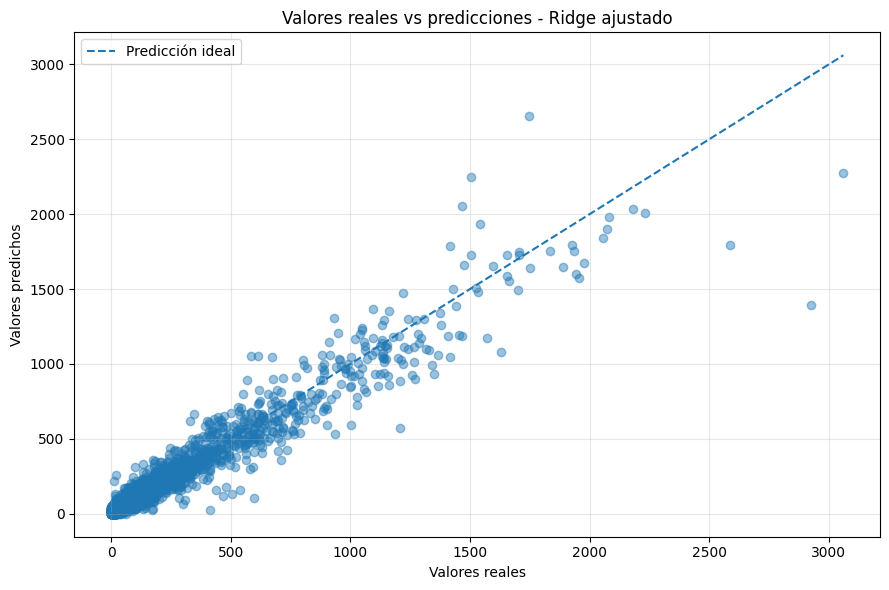

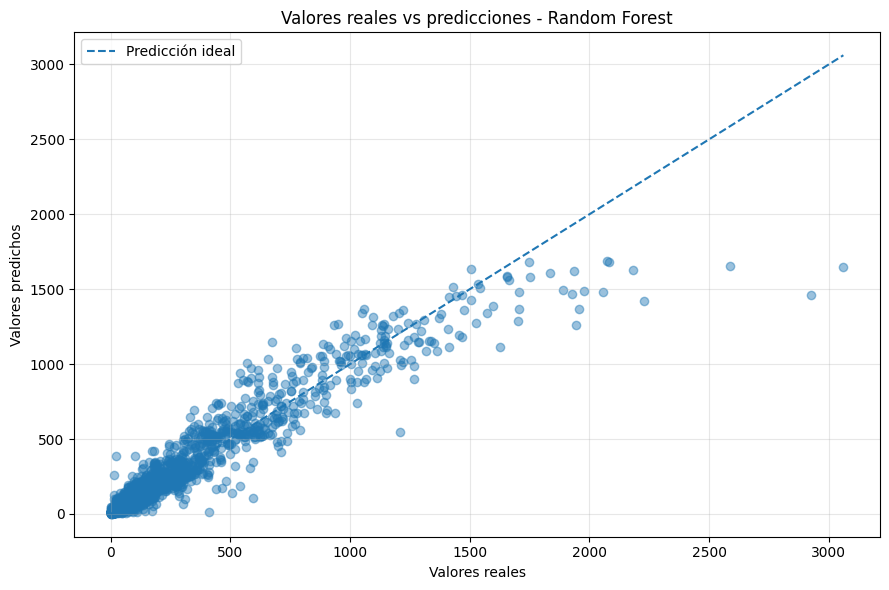

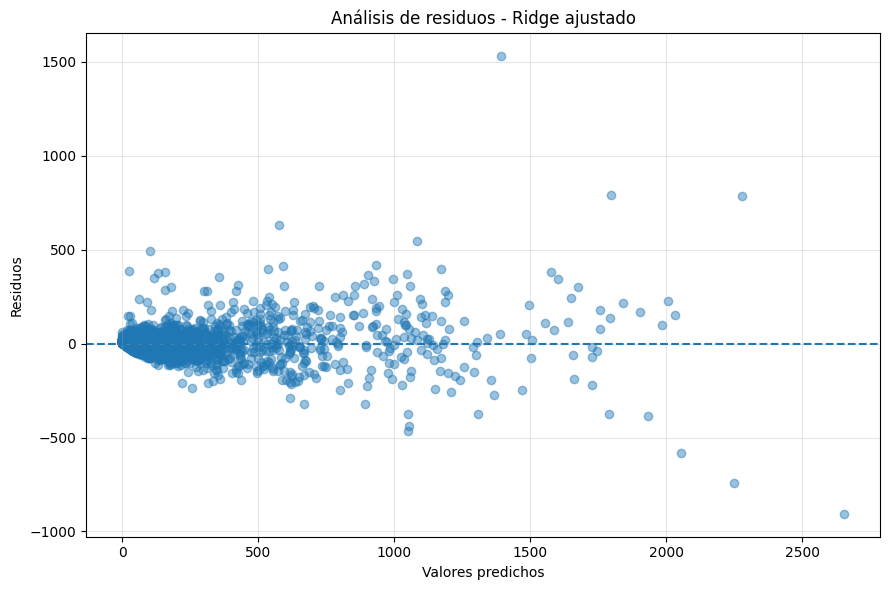

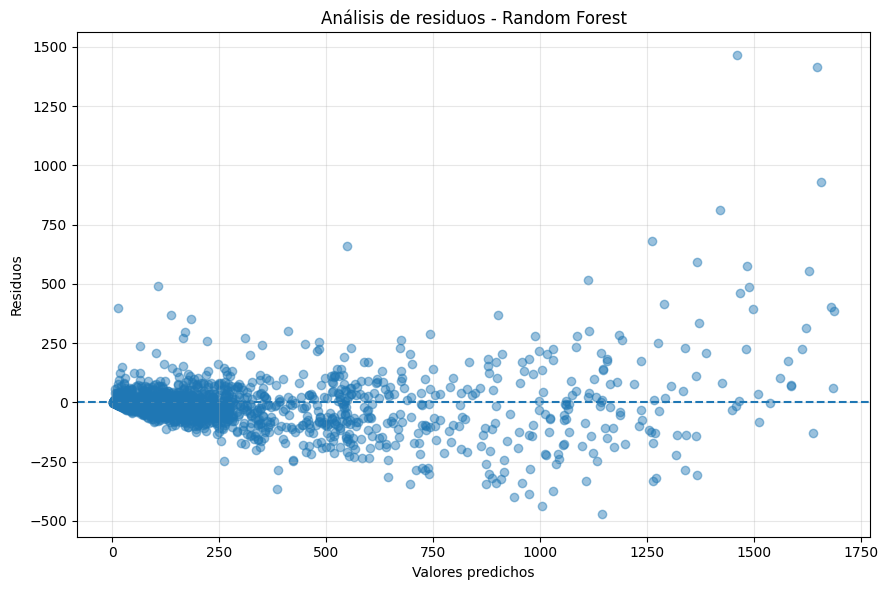

Evaluación gráfica finalizada.


In [27]:

# =====================================================
# EVALUACIÓN GRÁFICA FINAL DE LOS MODELOS
# =====================================================

residuos_ridge = y_real - pred_ridge
residuos_rf = y_real - pred_rf

# 1. VALORES REALES VS RIDGE

plt.figure(figsize=(9,6))
plt.scatter(y_real, pred_ridge, alpha=0.45)

limite_min = min(y_real.min(), pred_ridge.min())
limite_max = max(y_real.max(), pred_ridge.max())

plt.plot([limite_min, limite_max],
         [limite_min, limite_max],
         '--', label='Predicción ideal')

plt.title('Valores reales vs predicciones - Ridge ajustado')
plt.xlabel('Valores reales')
plt.ylabel('Valores predichos')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 2. VALORES REALES VS RANDOM FOREST

plt.figure(figsize=(9,6))
plt.scatter(y_real, pred_rf, alpha=0.45)

limite_min = min(y_real.min(), pred_rf.min())
limite_max = max(y_real.max(), pred_rf.max())

plt.plot([limite_min, limite_max],
         [limite_min, limite_max],
         '--', label='Predicción ideal')

plt.title('Valores reales vs predicciones - Random Forest')
plt.xlabel('Valores reales')
plt.ylabel('Valores predichos')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 3. RESIDUOS RIDGE AJUSTADO

plt.figure(figsize=(9,6))
plt.scatter(pred_ridge, residuos_ridge, alpha=0.45)
plt.axhline(0, linestyle='--')
plt.title('Análisis de residuos - Ridge ajustado')
plt.xlabel('Valores predichos')
plt.ylabel('Residuos')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 4. RESIDUOS RANDOM FOREST

plt.figure(figsize=(9,6))
plt.scatter(pred_rf, residuos_rf, alpha=0.45)
plt.axhline(0, linestyle='--')
plt.title('Análisis de residuos - Random Forest')
plt.xlabel('Valores predichos')
plt.ylabel('Residuos')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Evaluación gráfica finalizada.")


# 1. Interpretación de las gráficas
Gráfica 1. Valores reales vs. predicciones - Ridge ajustado
Buen ajuste general
Se observa que la mayoría de los puntos se encuentran cerca de la línea de predicción ideal, especialmente en los valores bajos y medios.

Sin embargo:
- En los volúmenes altos se presentan diferencias importantes entre los valores reales y los estimados.
- Algunos registros presentan subestimaciones y otros sobreestimaciones.
- El modelo conserva una relación adecuada entre los valores reales y las predicciones.
Interpretación: Ridge ajustado logra representar razonablemente el comportamiento general de los registros, aunque presenta dificultades para estimar valores extremos.

Gráfica 2. Valores reales vs. predicciones – Random Forest
Dificultad en volúmenes altos
El modelo presenta una concentración de predicciones en los valores bajos y medios.

Se identifica que:
- Las predicciones siguen una tendencia creciente respecto a los valores reales.
- En los registros de mayor volumen, el modelo tiende a subestimar considerablemente.
- Se observa una limitación para alcanzar algunos valores máximos reales.
Interpretación: Random Forest identifica patrones en los datos, pero presenta dificultades para representar los registros con volúmenes excepcionalmente altos.

Gráfica 3. Análisis de residuos – Ridge ajustado
Los residuos representan la diferencia entre el valor real y el valor predicho.

Se observa que:
- La mayoría de los residuos se concentran alrededor de cero.
- Existen valores atípicos con errores positivos y negativos importantes.
- La dispersión de los residuos aumenta a medida que crecen los valores predichos.
Interpretación: El modelo presenta un comportamiento aceptable en buena parte de las observaciones, pero evidencia heterocedasticidad, es decir, la variabilidad de los errores no permanece constante.

Gráfica 4. Análisis de residuos – Random Forest
Se identifica una mayor dispersión de los residuos en los valores predichos más elevados.

Los principales hallazgos son:
- Concentración de errores cerca de cero en volúmenes bajos.
- Incremento de la dispersión en volúmenes medios y altos.
- Presencia de errores positivos y negativos extremos.
- Dificultad para estimar adecuadamente algunos registros de mayor volumen.

Interpretación: Random Forest presenta una capacidad predictiva adecuada para muchos registros, pero su precisión disminuye cuando aumenta el volumen de los registros.

### Análisis gráfico y diagnóstico de los modelos de regresión

A partir de las gráficas obtenidas se realizó una evaluación visual del comportamiento de los modelos Ridge ajustado y Random Forest.

En primer lugar, las gráficas de valores reales frente a predicciones muestran que ambos modelos logran identificar la tendencia general de los datos. Sin embargo, se presentan diferencias importantes en los registros de mayor volumen, donde se observan subestimaciones y desviaciones respecto a la línea de predicción ideal.

En el modelo Ridge ajustado se evidencia una distribución relativamente cercana a la línea ideal, aunque existen observaciones con errores considerables. Por su parte, Random Forest presenta una tendencia a limitar las predicciones en los valores más elevados, lo que dificulta representar algunos registros extremos.

En cuanto al análisis de residuos, ambos modelos presentan una concentración de errores alrededor de cero. No obstante, se observa un incremento en la dispersión de los residuos a medida que aumentan los valores predichos. Este comportamiento evidencia la presencia de heterocedasticidad y de algunas observaciones atípicas.

Finalmente, al comparar las métricas de evaluación, Ridge ajustado obtiene un RMSE de 85.2074 y un coeficiente de determinación R² de 0.9300, mientras que Random Forest presenta un RMSE de 91.7832 y un R² de 0.9188. Aunque Random Forest obtiene un MAE ligeramente inferior, Ridge ajustado presenta un mejor comportamiento general frente a los errores de mayor magnitud.

Por lo anterior, se selecciona Ridge ajustado como modelo principal de predicción, conservando Random Forest como modelo de referencia para la comparación de resultados.

TOP 15 OFICINAS CON MAYOR ERROR


,Oficina de circunscripción consular,Registros,Volumen_real,MAE_Ridge,MAE_RF
41,C. MADRID,31,1812.35,250.68,335.69
7,C. BARCELONA,31,1250.19,205.88,179.75
84,C. VALENCIA ESP,31,1072.94,184.47,167.59
53,C. NUEVA YORK,31,1014.32,118.96,124.49
51,C. NEWARK,31,863.94,118.08,123.02
33,C. HOUSTON,31,655.52,116.35,136.66
75,C. SEVILLA,31,692.58,116.03,116.56
13,C. BILBAO,31,725.97,111.19,127.47
22,C. CHICAGO,31,577.10,108.91,113.33
40,C. LOS ANGELES,31,420.87,102.21,123.34


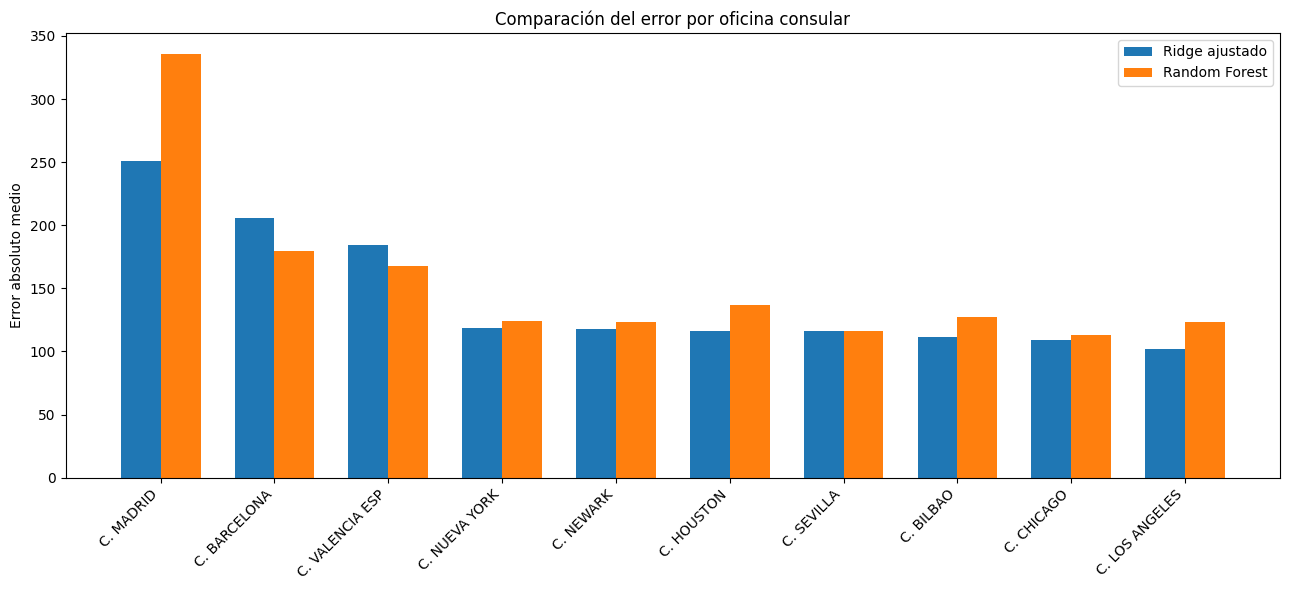

In [28]:

# =====================================================
# ANALISIS COMPARATIVO POR OFICINA
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Trabajar con los resultados finales
df_analisis = analisis_final.copy()

# Calcular errores absolutos
df_analisis["Error_Ridge"] = abs(
    df_analisis["Real"] - df_analisis["Pred_Ridge_Ajustado"]
)

df_analisis["Error_RF"] = abs(
    df_analisis["Real"] - df_analisis["Pred_RandomForest"]
)

# Agrupar resultados por oficina
resumen_oficinas = df_analisis.groupby(
    "Oficina de circunscripción consular"
).agg(
    Registros=("Real", "count"),
    Volumen_real=("Real", "mean"),
    MAE_Ridge=("Error_Ridge", "mean"),
    MAE_RF=("Error_RF", "mean")
).reset_index()

# Ordenar por mayor error de Ridge
resumen_oficinas = resumen_oficinas.sort_values(
    "MAE_Ridge", ascending=False
)

print("TOP 15 OFICINAS CON MAYOR ERROR")
display(resumen_oficinas.head(15).round(2))

# Comparación gráfica de las 10 oficinas principales
top10 = resumen_oficinas.head(10)

plt.figure(figsize=(13, 6))

x = np.arange(len(top10))
ancho = 0.35

plt.bar(
    x - ancho/2,
    top10["MAE_Ridge"],
    ancho,
    label="Ridge ajustado"
)

plt.bar(
    x + ancho/2,
    top10["MAE_RF"],
    ancho,
    label="Random Forest"
)

plt.xticks(
    x,
    top10["Oficina de circunscripción consular"],
    rotation=45,
    ha="right"
)

plt.ylabel("Error absoluto medio")
plt.title("Comparación del error por oficina consular")
plt.legend()
plt.tight_layout()
plt.show()


1. Interpretación de los resultados
La tabla presenta las 15 oficinas consulares con mayor error absoluto medio (MAE), comparando Ridge ajustado y Random Forest.

Los resultados más importantes son:
- Madrid: presenta el mayor error en ambos modelos. Ridge registra 250,68 y Random Forest 335,69.
- Barcelona: Random Forest obtiene un mejor resultado, con un MAE de 179,75 frente a 205,88 de Ridge.
- Valencia: Random Forest también presenta menor error: 167,59 frente a 184,47.
- Houston: Ridge obtiene mejor desempeño, con 116,35 frente a 136,66.
- Santiago: Random Forest obtiene un menor error, con 79,58 frente a 81,95.
La gráfica permite observar que el comportamiento de los modelos cambia dependiendo de la oficina consular. No existe un modelo que tenga el menor error en todas las oficinas.

### Análisis comparativo del error por oficina consular

Se realizó un análisis del error absoluto medio (MAE) para identificar las oficinas consulares en las que los modelos Ridge ajustado y Random Forest presentan mayores dificultades de predicción.

Los resultados muestran que la oficina consular de Madrid registra el mayor error en ambos modelos, con un MAE de 250,68 para Ridge y 335,69 para Random Forest. También se identificaron errores elevados en Barcelona y Valencia, oficinas que presentan volúmenes promedio de registros superiores a los de otras sedes analizadas.

La comparación evidencia que el desempeño de los modelos varía según la oficina. Random Forest presenta mejores resultados en algunas sedes, como Barcelona y Valencia, mientras que Ridge ajustado obtiene menores errores en otras, como Madrid, Houston y Los Ángeles.

En conclusión, el comportamiento de las predicciones depende de las características particulares de cada oficina consular. Por esta razón, resulta importante evaluar los resultados de manera individual y no únicamente mediante métricas globales.

In [29]:

# ==========================================
# VERIFICACION DE MODELOS Y DATOS DISPONIBLES
# ==========================================

print("MODELOS ENTRENADOS DISPONIBLES:")

for nombre, objeto in globals().items():
    if not nombre.startswith("_"):
        if hasattr(objeto, "coef_") or hasattr(objeto, "feature_importances_"):
            print(nombre, "|", type(objeto).__name__)

print("\nMATRICES DE DATOS DISPONIBLES:")

for nombre in ["X_train", "X_test", "X_prueba",
               "X_entrenamiento", "variables_predictoras"]:
    if nombre in globals():
        objeto = globals()[nombre]
        print(nombre, "|", type(objeto).__name__,
              "|", getattr(objeto, "shape", "Sin dimensiones"))

print("\nVARIABLES PREDICTORAS:")
print(variables_predictoras)


MODELOS ENTRENADOS DISPONIBLES:
RandomForestRegressor | ABCMeta

MATRICES DE DATOS DISPONIBLES:
X_train | DataFrame | (9775, 13)
X_test | DataFrame | (2703, 13)
variables_predictoras | list | Sin dimensiones

VARIABLES PREDICTORAS:
['Año', 'Numero_mes', 'Trimestre', 'Mes_seno', 'Mes_coseno', 'Rezago_1', 'Rezago_2', 'Rezago_3', 'Rezago_6', 'Rezago_12', 'Promedio_movil_3', 'Promedio_movil_6']


Lo que muestran tus resultados
- Entrenamiento: 9.775 registros y 13 columnas.
- Prueba: 2.703 registros y 13 columnas.
- Variables predictoras declaradas: 12.
- Random Forest aparece como ABCMeta, lo que indica que estamos viendo la clase importada, no necesariamente el modelo entrenado.
- Todavía no hemos identificado el objeto del Ridge ajustado.

In [30]:

# ==========================================
# IDENTIFICACION DE MODELOS Y VARIABLES
# ==========================================

print("COLUMNAS DE X_train:")
print(list(X_train.columns))

print("\nCOLUMNAS DE X_test:")
print(list(X_test.columns))

print("\nCLAVES DE PREDICCIONES:")
if "predicciones" in globals():
    print(predicciones.keys())

print("\nOBJETOS RELACIONADOS CON MODELOS:")

for nombre, objeto in list(globals().items()):
    if any(p in nombre.lower() for p in
           ["modelo", "ridge", "forest", "regres", "pipe"]):
        print(
            nombre,
            "|",
            type(objeto).__name__,
            "|",
            "Coeficientes:", hasattr(objeto, "coef_"),
            "|",
            "Importancia:", hasattr(objeto, "feature_importances_")
        )


COLUMNAS DE X_train:
['Año', 'Numero_mes', 'Trimestre', 'Mes_seno', 'Mes_coseno', 'Rezago_1', 'Rezago_2', 'Rezago_3', 'Rezago_6', 'Rezago_12', 'Promedio_movil_3', 'Promedio_movil_6', 'Oficina de circunscripción consular']

COLUMNAS DE X_test:
['Año', 'Numero_mes', 'Trimestre', 'Mes_seno', 'Mes_coseno', 'Rezago_1', 'Rezago_2', 'Rezago_3', 'Rezago_6', 'Rezago_12', 'Promedio_movil_3', 'Promedio_movil_6', 'Oficina de circunscripción consular']

CLAVES DE PREDICCIONES:
dict_keys(['Regresión Lineal', 'Ridge', 'Random Forest', 'HistGradientBoosting'])

OBJETOS RELACIONADOS CON MODELOS:
panel_modelo | DataFrame | Coeficientes: False | Importancia: False
columnas_modelo | list | Coeficientes: False | Importancia: False
modelo_regresion | DataFrame | Coeficientes: False | Importancia: False
Pipeline | ABCMeta | Coeficientes: False | Importancia: False
LinearRegression | ABCMeta | Coeficientes: False | Importancia: False
Ridge | ABCMeta | Coeficientes: False | Importancia: False
RandomForestRegre

In [31]:

# ==========================================
# INSPECCION DE MODELOS ENTRENADOS
# ==========================================

print("1. MODELOS ENTRENADOS")

for nombre, modelo in modelos_entrenados.items():
    print("\nModelo:", nombre)
    print("Tipo:", type(modelo).__name__)

    if hasattr(modelo, "steps"):
        print("Componentes del Pipeline:")
        for paso, componente in modelo.steps:
            print(" -", paso, ":", type(componente).__name__)

    elif hasattr(modelo, "feature_importances_"):
        print("Tiene importancia de variables")

    elif hasattr(modelo, "coef_"):
        print("Tiene coeficientes")

print("\n2. DICCIONARIO DE MODELOS")

for nombre, modelo in modelos.items():
    print(nombre, ":", type(modelo).__name__)

print("\n3. DIMENSIONES DE LOS DATOS")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Variables predictoras:", len(variables_predictoras))
print("Columnas:", list(X_train.columns))


1. MODELOS ENTRENADOS

Modelo: Regresión Lineal
Tipo: Pipeline
Componentes del Pipeline:
 - preprocesamiento : ColumnTransformer
 - modelo : LinearRegression

Modelo: Ridge
Tipo: Pipeline
Componentes del Pipeline:
 - preprocesamiento : ColumnTransformer
 - modelo : Ridge

Modelo: Random Forest
Tipo: Pipeline
Componentes del Pipeline:
 - preprocesamiento : ColumnTransformer
 - modelo : RandomForestRegressor

Modelo: HistGradientBoosting
Tipo: Pipeline
Componentes del Pipeline:
 - preprocesamiento : ColumnTransformer
 - modelo : HistGradientBoostingRegressor

2. DICCIONARIO DE MODELOS
Regresión Lineal : LinearRegression
Ridge : Ridge
Random Forest : RandomForestRegressor
HistGradientBoosting : HistGradientBoostingRegressor

3. DIMENSIONES DE LOS DATOS
X_train: (9775, 13)
X_test: (2703, 13)
Variables predictoras: 12
Columnas: ['Año', 'Numero_mes', 'Trimestre', 'Mes_seno', 'Mes_coseno', 'Rezago_1', 'Rezago_2', 'Rezago_3', 'Rezago_6', 'Rezago_12', 'Promedio_movil_3', 'Promedio_movil_6', 'Of

importante en los resultados:
- Regresión Lineal: Pipeline con preprocesamiento y regresión lineal.
- Ridge: Pipeline con preprocesamiento y regularización.
- Random Forest: Pipeline con preprocesamiento y árboles de decisión.
- HistGradientBoosting: Pipeline con preprocesamiento y potenciación de gradiente.

In [32]:

# ==========================================
# VERIFICACION DE VARIABLES PREDICTORAS
# ==========================================

columnas_train = list(X_train.columns)
columnas_declaradas = list(variables_predictoras)

print("COLUMNAS DE X_TRAIN:", len(columnas_train))
print("VARIABLES DECLARADAS:", len(columnas_declaradas))

print("\nCOLUMNAS DE X_TRAIN:")
for columna in columnas_train:
    print("-", columna)

print("\nCOLUMNAS QUE NO ESTAN EN VARIABLES_PREDICTORAS:")
extras = [c for c in columnas_train if c not in columnas_declaradas]
print(extras)

print("\nVARIABLES DECLARADAS QUE NO ESTAN EN X_TRAIN:")
faltantes = [c for c in columnas_declaradas if c not in columnas_train]
print(faltantes)


COLUMNAS DE X_TRAIN: 13
VARIABLES DECLARADAS: 12

COLUMNAS DE X_TRAIN:
- Año
- Numero_mes
- Trimestre
- Mes_seno
- Mes_coseno
- Rezago_1
- Rezago_2
- Rezago_3
- Rezago_6
- Rezago_12
- Promedio_movil_3
- Promedio_movil_6
- Oficina de circunscripción consular

COLUMNAS QUE NO ESTAN EN VARIABLES_PREDICTORAS:
['Oficina de circunscripción consular']

VARIABLES DECLARADAS QUE NO ESTAN EN X_TRAIN:
[]


IMPORTANCIA DE VARIABLES - RANDOM FOREST


,Importancia
Variable_original,
Rezago_1,7.479362e-01
Promedio_movil_3,1.045540e-01
Rezago_2,3.520576e-02
Rezago_6,2.122103e-02
Rezago_12,1.585333e-02
...,...
Oficina de circunscripción consular_C. OSLO,1.290583e-07
Oficina de circunscripción consular_C. BANGKOK,3.885730e-08
Oficina de circunscripción consular_C. DUBLIN,3.876470e-08


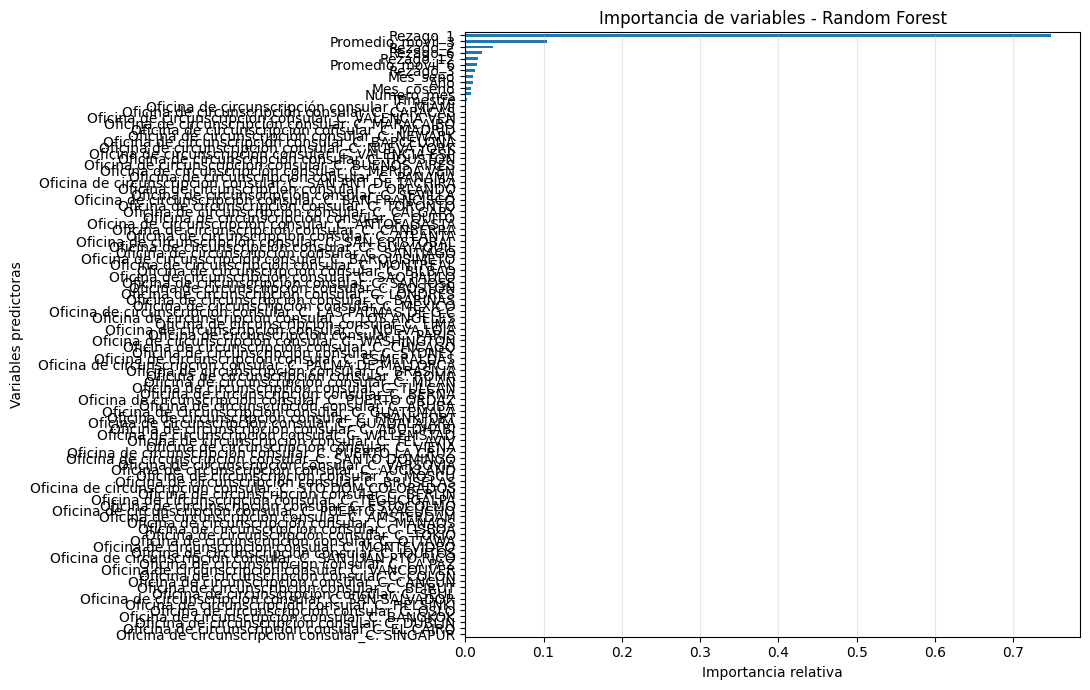

Suma de importancias: 1.0


In [33]:

# =====================================================
# ANALISIS DE IMPORTANCIA DE VARIABLES - RANDOM FOREST
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Recuperar el modelo entrenado
modelo_rf = modelos_entrenados["Random Forest"]

# Obtener los componentes del Pipeline
preprocesador = modelo_rf.named_steps["preprocesamiento"]
modelo = modelo_rf.named_steps["modelo"]

# Obtener nombres de variables transformadas
nombres_transformados = preprocesador.get_feature_names_out()

# Obtener importancia de cada variable
importancias = modelo.feature_importances_

# Crear tabla
tabla_importancia = pd.DataFrame({
    "Variable_transformada": nombres_transformados,
    "Importancia": importancias
})

# Agrupar las categorías de variables originales
columnas_originales = list(X_train.columns)

def identificar_variable(nombre):
    nombre = str(nombre)

    for columna in sorted(columnas_originales, key=len, reverse=True):
        if (nombre.endswith(columna) or
            nombre.startswith(columna + "_")):
            return columna

    return nombre.split("__")[-1]

tabla_importancia["Variable_original"] = (
    tabla_importancia["Variable_transformada"]
    .apply(identificar_variable)
)

# Sumar importancias de categorías
importancia_agrupada = (
    tabla_importancia
    .groupby("Variable_original")["Importancia"]
    .sum()
    .sort_values(ascending=False)
)

print("IMPORTANCIA DE VARIABLES - RANDOM FOREST")
display(importancia_agrupada.to_frame())

# Grafica
plt.figure(figsize=(11, 7))

importancia_agrupada.sort_values().plot(
    kind="barh"
)

plt.title("Importancia de variables - Random Forest")
plt.xlabel("Importancia relativa")
plt.ylabel("Variables predictoras")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Verificar suma de importancias
print("Suma de importancias:",
      importancia_agrupada.sum())


IMPORTANCIA DE LAS 13 COLUMNAS DE ENTRADA


,Importancia (%)
Variable,
Rezago_1,74.794
Promedio_movil_3,10.455
Rezago_2,3.521
Rezago_6,2.122
Rezago_12,1.585
Promedio_movil_6,1.557
Rezago_3,1.280
Oficina de circunscripción consular,1.063
Mes_seno,1.047


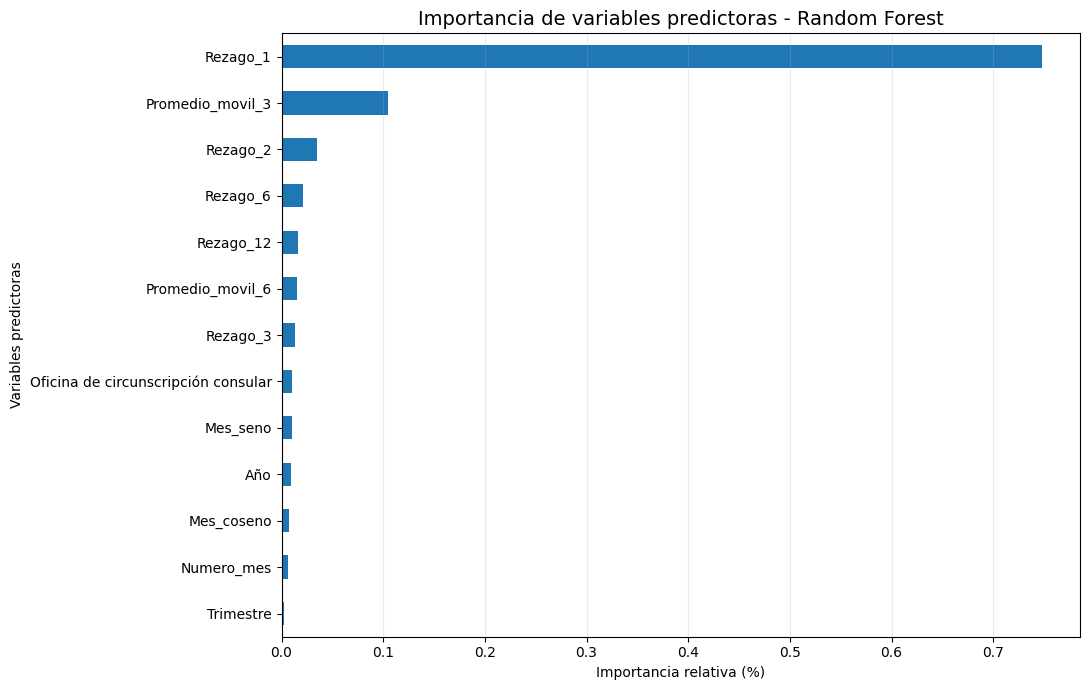

Total de variables: 13
Suma de importancia: 1.0


In [34]:

# =====================================================
# GRAFICA CORREGIDA: 12 VARIABLES ORIGINALES
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt

nombres = preprocesador.get_feature_names_out()
importancias = modelo.feature_importances_

oficina = "Oficina de circunscripción consular"
columnas = list(X_train.columns)

resultados = []

for nombre, importancia in zip(nombres, importancias):

    nombre = str(nombre)

    # Agrupar todas las oficinas consulares
    if oficina in nombre:
        variable = oficina

    else:
        nombre_limpio = nombre.split("__")[-1]

        variable = nombre_limpio

        for columna in columnas:
            if (nombre_limpio == columna or
                nombre_limpio.startswith(columna + "_")):
                variable = columna
                break

    resultados.append({
        "Variable": variable,
        "Importancia": importancia
    })

tabla_corregida = pd.DataFrame(resultados)

tabla_corregida = (
    tabla_corregida.groupby("Variable")["Importancia"]
    .sum()
    .sort_values(ascending=False)
)

print("IMPORTANCIA DE LAS 13 COLUMNAS DE ENTRADA")
display(
    (tabla_corregida * 100)
    .round(3)
    .rename("Importancia (%)")
    .to_frame()
)

# Grafica profesional
plt.figure(figsize=(11, 7))

tabla_corregida.sort_values().plot(
    kind="barh"
)

plt.title(
    "Importancia de variables predictoras - Random Forest",
    fontsize=14
)

plt.xlabel("Importancia relativa (%)")
plt.ylabel("Variables predictoras")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

print("Total de variables:", len(tabla_corregida))
print("Suma de importancia:", tabla_corregida.sum())


Análisis de importancia de las variables predictoras

Los resultados obtenidos mediante el modelo Random Forest evidencian que la variable Rezago_1 presenta la mayor importancia predictiva, con un valor aproximado del 74,79 %. En segundo lugar, se encuentra Promedio_movil_3, con una participación del 10,46 %.

Este comportamiento indica que los registros históricos recientes tienen una influencia considerable en las estimaciones del volumen de registros consulares. Asimismo, los rezagos de dos, seis y doce períodos complementan la información utilizada por el modelo.

Estos resultados resaltan la importancia de incorporar variables temporales en los modelos de predicción.

COEFICIENTES DEL MODELO RIDGE


,Coeficiente_neto,Magnitud_total
Variable_original,,
Oficina de circunscripción consular,-0.0000,1274.6059
Rezago_1,124.0835,124.0835
Trimestre,-45.5142,45.5142
Promedio_movil_3,44.3032,44.3032
Promedio_movil_6,35.2135,35.2135
Rezago_2,34.1053,34.1053
Rezago_3,-29.0487,29.0487
Mes_seno,-23.3497,23.3497
Numero_mes,21.7391,21.7391


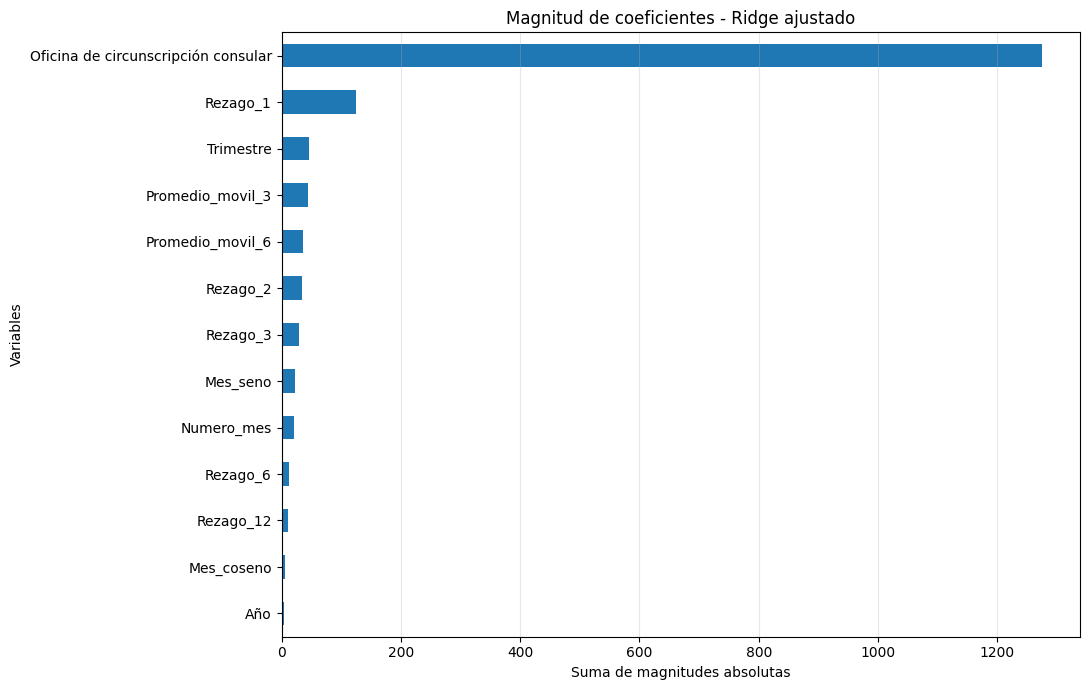


Análisis de coeficientes terminado.


In [36]:

# =====================================================
# ANALISIS DE COEFICIENTES - RIDGE AJUSTADO
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Recuperar el Pipeline Ridge entrenado
modelo_ridge = modelos_entrenados["Ridge"]

# Obtener preprocesador y estimador
preprocesador_ridge = modelo_ridge.named_steps["preprocesamiento"]
estimador_ridge = modelo_ridge.named_steps["modelo"]

# Obtener nombres de variables transformadas
nombres = preprocesador_ridge.get_feature_names_out()

# Extraer coeficientes
coeficientes = estimador_ridge.coef_.ravel()

# Crear tabla
tabla_coeficientes = pd.DataFrame({
    "Variable": nombres,
    "Coeficiente": coeficientes
})

# Agrupar categorías de oficinas consulares
col_oficina = "Oficina de circunscripción consular"

columnas_originales = list(X_train.columns)

def agrupar_variable(nombre):

    nombre = str(nombre)

    if col_oficina in nombre:
        return col_oficina

    nombre = nombre.split("__")[-1]

    for columna in sorted(
        columnas_originales,
        key=len,
        reverse=True
    ):
        if nombre == columna or nombre.startswith(columna + "_"):
            return columna

    return nombre

tabla_coeficientes["Variable_original"] = (
    tabla_coeficientes["Variable"].apply(agrupar_variable)
)

# Agrupar coeficientes de variables categóricas
resumen_ridge = (
    tabla_coeficientes
    .groupby("Variable_original")
    .agg(
        Coeficiente_neto=("Coeficiente", "sum"),
        Magnitud_total=("Coeficiente", lambda x: np.abs(x).sum())
    )
    .sort_values("Magnitud_total", ascending=False)
)

print("COEFICIENTES DEL MODELO RIDGE")
display(resumen_ridge.round(4))

# Gráfica de magnitud
plt.figure(figsize=(11, 7))

resumen_ridge["Magnitud_total"].sort_values().plot(
    kind="barh"
)

plt.title("Magnitud de coeficientes - Ridge ajustado")
plt.xlabel("Suma de magnitudes absolutas")
plt.ylabel("Variables")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nAnálisis de coeficientes terminado.")


El rezago 1 es la variable numérica más influyente: su coeficiente es 124,08. Esto indica que el volumen del mes inmediatamente anterior aporta mucha información para estimar el volumen del mes actual.



El promedio móvil de 3 meses también tiene bastante peso: su coeficiente es 44,30. Esto respalda la importancia del comportamiento reciente de cada oficina.

In [37]:
from sklearn.base import clone
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import VotingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 1. Quinto modelo: Árbol de Decisión
arbol = Pipeline([
    ("preprocesamiento",
     clone(modelos_entrenados["Ridge"].named_steps["preprocesamiento"])),
    ("modelo", DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=5,
        random_state=42
    ))
])

arbol.fit(X_train, y_train)

# 2. Ensamble: Voting Regressor
voting = VotingRegressor(estimators=[
    ("ridge", clone(modelos_entrenados["Ridge"])),
    ("random_forest", clone(modelos_entrenados["Random Forest"])),
    ("hist_gradient", clone(modelos_entrenados["HistGradientBoosting"]))
])

voting.fit(X_train, y_train)

# 3. Guardar modelos y predicciones
modelos_entrenados["Árbol de Decisión"] = arbol
modelos_entrenados["Voting Regressor"] = voting

predicciones["Árbol de Decisión"] = arbol.predict(X_test)
predicciones["Voting Regressor"] = voting.predict(X_test)

# 4. Comparar resultados en los datos de prueba
resultados_nuevos = []

for nombre in ["Árbol de Decisión", "Voting Regressor"]:
    y_pred = predicciones[nombre]

    resultados_nuevos.append({
        "Modelo": nombre,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

tabla_nuevos = pd.DataFrame(resultados_nuevos)
display(tabla_nuevos.round(4))

,Modelo,MAE,RMSE,R2
0,Árbol de Decisión,53.1387,117.0548,0.8679
1,Voting Regressor,41.9088,86.0652,0.9286


El Voting Regressor obtuvo el mejor MAE hasta ahora: 41,91, es decir, el menor error absoluto promedio entre los modelos evaluados. El Árbol de Decisión quedó por debajo de los demás, con MAE de 53,14 y R^2 de 0,8679.

____
Validación cruzada temporal y ajuste
Vamos a utilizar MAE como métrica principal, porque expresa directamente cuántos registros se equivoca el modelo, en promedio. Además, usaremos cuatro divisiones temporales para evitar mezclar meses futuros con meses pasados.

In [39]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
import numpy as np
import pandas as pd

# 1. Crear periodos cronológicos usando año y mes
periodos = (
    X_train["Año"].astype(int) * 100
    + X_train["Numero_mes"].astype(int)
).to_numpy()

periodos_unicos = np.sort(np.unique(periodos))

# 2. Crear divisiones temporales por mes completo
tscv = TimeSeriesSplit(n_splits=4)
cv_temporal = []

for indices_train, indices_validacion in tscv.split(periodos_unicos):
    meses_train = periodos_unicos[indices_train]
    meses_validacion = periodos_unicos[indices_validacion]

    filas_train = np.where(np.isin(periodos, meses_train))[0]
    filas_validacion = np.where(np.isin(periodos, meses_validacion))[0]

    cv_temporal.append((filas_train, filas_validacion))

print("Validación temporal creada:", len(cv_temporal), "divisiones")

# 3. Ajustar Ridge
busqueda_ridge = GridSearchCV(
    estimator=clone(modelos_entrenados["Ridge"]),
    param_grid={
        "modelo__alpha": [0.01, 0.1, 1, 10, 100]
    },
    scoring="neg_mean_absolute_error",
    cv=cv_temporal,
    n_jobs=-1
)

busqueda_ridge.fit(X_train, y_train)

# 4. Ajustar Random Forest
busqueda_rf = RandomizedSearchCV(
    estimator=clone(modelos_entrenados["Random Forest"]),
    param_distributions={
        "modelo__n_estimators": [150, 250, 350],
        "modelo__max_depth": [10, 15, 20, None],
        "modelo__min_samples_leaf": [2, 4, 6],
        "modelo__max_features": [0.7, 1.0]
    },
    n_iter=8,
    scoring="neg_mean_absolute_error",
    cv=cv_temporal,
    random_state=42,
    n_jobs=-1
)

busqueda_rf.fit(X_train, y_train)

# 5. Ajustar HistGradientBoosting
busqueda_hgb = RandomizedSearchCV(
    estimator=clone(modelos_entrenados["HistGradientBoosting"]),
    param_distributions={
        "modelo__max_iter": [100, 200, 300],
        "modelo__learning_rate": [0.03, 0.05, 0.08, 0.1],
        "modelo__max_leaf_nodes": [15, 20, 31],
        "modelo__l2_regularization": [0, 0.1, 1]
    },
    n_iter=8,
    scoring="neg_mean_absolute_error",
    cv=cv_temporal,
    random_state=42,
    n_jobs=-1
)

busqueda_hgb.fit(X_train, y_train)

# 6. Resumen de resultados de validación cruzada
resultados_cv = pd.DataFrame([
    {
        "Modelo": "Ridge",
        "MAE_CV": -busqueda_ridge.best_score_,
        "Mejores parámetros": busqueda_ridge.best_params_
    },
    {
        "Modelo": "Random Forest",
        "MAE_CV": -busqueda_rf.best_score_,
        "Mejores parámetros": busqueda_rf.best_params_
    },
    {
        "Modelo": "HistGradientBoosting",
        "MAE_CV": -busqueda_hgb.best_score_,
        "Mejores parámetros": busqueda_hgb.best_params_
    }
])

display(resultados_cv.round(4))

Validación temporal creada: 4 divisiones


,Modelo,MAE_CV,Mejores parámetros
0,Ridge,48.5659,{'modelo__alpha': 100}
1,Random Forest,41.2574,"{'modelo__n_estimators': 350, 'modelo__min_sam..."
2,HistGradientBoosting,43.8364,"{'modelo__max_leaf_nodes': 31, 'modelo__max_it..."


Random Forest obtuvo el menor MAE en la validación cruzada temporal, con 41,26 registros de error promedio. Esto lo convierte en el candidato principal para la evaluación final.

In [40]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Recuperar los mejores modelos encontrados
modelos_optimizados = {
    "Ridge optimizado": busqueda_ridge.best_estimator_,
    "Random Forest optimizado": busqueda_rf.best_estimator_,
    "HistGradientBoosting optimizado": busqueda_hgb.best_estimator_
}

resultados_finales = []

for nombre, modelo_actual in modelos_optimizados.items():

    # Predicciones en entrenamiento y prueba
    pred_train = np.maximum(modelo_actual.predict(X_train), 0)
    pred_test = np.maximum(modelo_actual.predict(X_test), 0)

    resultados_finales.append({
        "Modelo": nombre,
        "MAE_entrenamiento": mean_absolute_error(y_train, pred_train),
        "MAE_prueba": mean_absolute_error(y_test, pred_test),
        "RMSE_prueba": np.sqrt(mean_squared_error(y_test, pred_test)),
        "R2_prueba": r2_score(y_test, pred_test),
        "MAE_CV": -(
            busqueda_ridge.best_score_ if "Ridge" in nombre
            else busqueda_rf.best_score_ if "Random Forest" in nombre
            else busqueda_hgb.best_score_
        )
    })

tabla_evaluacion = pd.DataFrame(resultados_finales)

display(tabla_evaluacion.round(4))

# Mostrar los parámetros seleccionados
print("\nMEJORES PARÁMETROS ENCONTRADOS")

for nombre, busqueda in [
    ("Ridge", busqueda_ridge),
    ("Random Forest", busqueda_rf),
    ("HistGradientBoosting", busqueda_hgb)
]:
    print(f"\n{nombre}:")
    print(busqueda.best_params_)

,Modelo,MAE_entrenamiento,MAE_prueba,RMSE_prueba,R2_prueba,MAE_CV
0,Ridge optimizado,42.6663,43.3968,84.3759,0.9313,48.5659
1,Random Forest optimizado,26.8914,41.8095,88.2506,0.9249,41.2574
2,HistGradientBoosting optimizado,30.4460,43.2487,93.3419,0.9160,43.8364



MEJORES PARÁMETROS ENCONTRADOS

Ridge:
{'modelo__alpha': 100}

Random Forest:
{'modelo__n_estimators': 350, 'modelo__min_samples_leaf': 6, 'modelo__max_features': 0.7, 'modelo__max_depth': None}

HistGradientBoosting:
{'modelo__max_leaf_nodes': 31, 'modelo__max_iter': 100, 'modelo__learning_rate': 0.05, 'modelo__l2_regularization': 1}


#Interpretación de la evaluación

Candidato principal: Random Forest optimizado
Como definimos el MAE como métrica principal, Random Forest es el candidato más conveniente:
- MAE de prueba: 41,81 registros.
- MAE de validación cruzada: 41,26 registros.
- R² de prueba: 0,9249.
Su resultado en validación cruzada y prueba es bastante parecido, lo cual es una buena señal de consistencia.

Sin embargo, hay que reconocer una diferencia entre entrenamiento y prueba: el MAE pasa de 26,89 a 41,81. Esto indica cierto sobreajuste. No significa que el modelo no sirva, pero sí que debemos documentarlo.

Ridge optimizado también es competitivo: tiene un MAE de prueba de 43,40, pero obtiene el mejor RMSE (84,38) y el mejor R² (0,9313), además de una diferencia menor entre entrenamiento y prueba.

Resumen de errores:


,Real,Predicho,Error,Error_absoluto
count,2703.00,2703.00,2703.00,2703.00
mean,197.27,203.42,-6.15,41.81
std,322.08,304.22,88.05,77.73
min,1.00,2.69,-444.70,0.00
25%,19.00,23.24,-22.54,5.09
50%,71.00,75.10,-4.56,14.52
75%,210.50,228.21,6.13,44.74
max,3061.00,1764.57,1461.11,1461.11


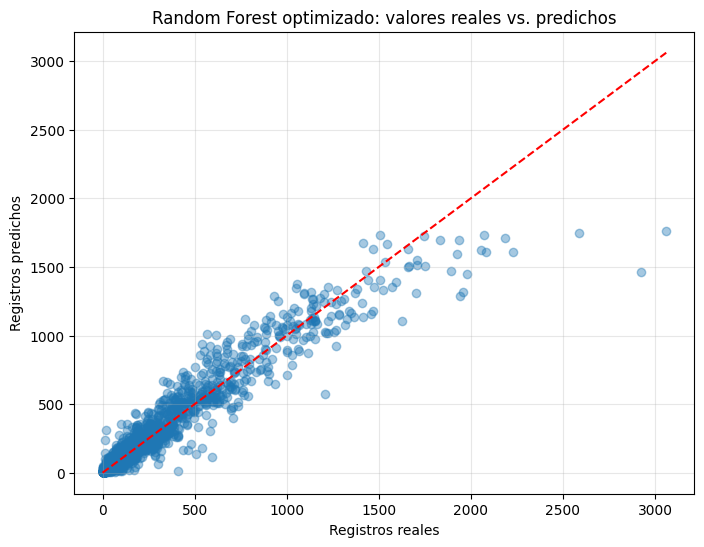

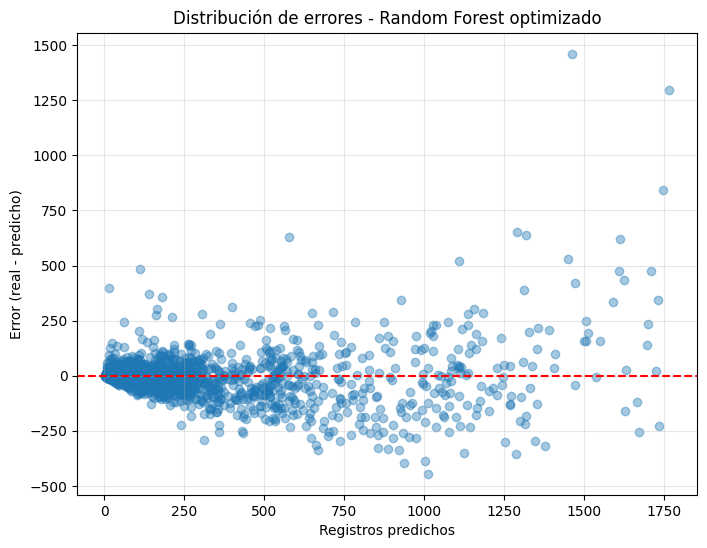

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# Modelo candidato
modelo_final = busqueda_rf.best_estimator_

# Predicciones del conjunto de prueba
pred_final = np.maximum(modelo_final.predict(X_test), 0)

# Tabla de errores
diagnostico = pd.DataFrame({
    "Real": np.asarray(y_test),
    "Predicho": pred_final
})

diagnostico["Error"] = diagnostico["Real"] - diagnostico["Predicho"]
diagnostico["Error_absoluto"] = diagnostico["Error"].abs()

print("Resumen de errores:")
display(diagnostico[
    ["Real", "Predicho", "Error", "Error_absoluto"]
].describe().round(2))

# Gráfica de valores reales frente a predichos
plt.figure(figsize=(8, 6))
plt.scatter(diagnostico["Real"], diagnostico["Predicho"], alpha=0.4)
limite = max(diagnostico["Real"].max(), diagnostico["Predicho"].max())
plt.plot([0, limite], [0, limite], "r--")
plt.xlabel("Registros reales")
plt.ylabel("Registros predichos")
plt.title("Random Forest optimizado: valores reales vs. predichos")
plt.grid(alpha=0.3)
plt.show()

# Gráfica de residuos
plt.figure(figsize=(8, 6))
plt.scatter(diagnostico["Predicho"], diagnostico["Error"], alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Registros predichos")
plt.ylabel("Error (real - predicho)")
plt.title("Distribución de errores - Random Forest optimizado")
plt.grid(alpha=0.3)
plt.show()

Las gráficas muestran que el modelo está funcionando razonablemente bien, pero también dejan ver una limitación que debemos explicar en el informe.
Interpretación del diagnóstico
1. Error promedio
- MAE: 41,81 registros.
- Error medio: −6,15 registros. Como calculamos el error restando real menos predicho, el signo negativo indica una ligera tendencia general a sobreestimar.
- Error absoluto mediano: 14,52 registros. La mitad de las predicciones tiene un error absoluto igual o inferior a ese valor.
2. Valores reales frente a predichos

La mayoría de los puntos se aproxima a la línea roja, lo que indica concordancia entre valores reales y estimados. Sin embargo, en los volúmenes más altos el modelo tiende a quedarse corto: por ejemplo, el valor real máximo fue 3.061 y la predicción máxima fue 1.764,57.

3. Distribución de errores

La dispersión aumenta a medida que crece el volumen predicho. Esto evidencia que el modelo comete errores más grandes en oficinas o periodos de alto volumen. También hay algunos casos de subestimación considerable.

Conclusión para el informe: Random Forest optimizado presenta un desempeño adecuado para estimar el volumen mensual habitual, pero tiene dificultades para anticipar picos excepcionales de demanda. Por tanto, sus predicciones deben utilizarse como apoyo a la planificación y no como cifras exactas, especialmente en oficinas de alto volumen.

In [42]:
import joblib
import json
import os

# Modelo seleccionado
modelo_final = busqueda_rf.best_estimator_

# Identificar la variable categórica
columna_oficina = "Oficina de circunscripción consular"

# Guardar modelo y datos necesarios para la aplicación
paquete_modelo = {
    "modelo": modelo_final,
    "columnas": list(X_train.columns),
    "oficinas": sorted(
        X_train[columna_oficina].dropna().astype(str).unique().tolist()
    ),
    "nombre": "Random Forest optimizado",
    "metrica_principal": "MAE",
    "mae_validacion": float(-busqueda_rf.best_score_),
    "mae_prueba": float(mean_absolute_error(y_test, pred_final)),
    "rmse_prueba": float(np.sqrt(mean_squared_error(y_test, pred_final))),
    "r2_prueba": float(r2_score(y_test, pred_final))
}

ruta_modelo = "/content/modelo_random_forest.joblib"

joblib.dump(paquete_modelo, ruta_modelo)

print("Modelo guardado correctamente.")
print("Archivo:", ruta_modelo)
print("Tamaño:", round(os.path.getsize(ruta_modelo) / 1024, 2), "KB")
print("Número de variables:", len(paquete_modelo["columnas"]))

# Descargar el archivo a tu computador
from google.colab import files
files.download(ruta_modelo)

Modelo guardado correctamente.
Archivo: /content/modelo_random_forest.joblib
Tamaño: 40372.62 KB
Número de variables: 13


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:
import os

ruta = "/content/modelo_random_forest.joblib"

if os.path.exists(ruta):
    print("Correcto: el modelo está disponible.")
else:
    print("Debes volver a cargar el modelo descargado.")

Correcto: el modelo está disponible.


In [44]:

%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import os

st.set_page_config(
    page_title="Predicción de registros consulares",
    page_icon="📊",
    layout="centered"
)

@st.cache_resource
def cargar_modelo():
    return joblib.load("modelo_random_forest.joblib")

st.title("Predicción del volumen de registros consulares")
st.write(
    "Herramienta de predicción mensual por oficina consular, "
    "desarrollada mediante aprendizaje automático."
)

try:
    paquete = cargar_modelo()
    modelo = paquete["modelo"]
    columnas = paquete["columnas"]
    oficinas = paquete["oficinas"]
except Exception as e:
    st.error(f"No fue posible cargar el modelo: {e}")
    st.stop()

st.info(
    "Selecciona la oficina, el año y el mes que deseas estimar. "
    "Debes ingresar los registros reales de los 12 meses anteriores."
)

with st.form("formulario_prediccion"):

    oficina = st.selectbox("Oficina consular", oficinas)

    col1, col2 = st.columns(2)

    with col1:
        anio = st.number_input(
            "Año de predicción",
            min_value=2014,
            max_value=2100,
            value=2027,
            step=1
        )

    with col2:
        nombres_meses = [
            "Enero", "Febrero", "Marzo", "Abril",
            "Mayo", "Junio", "Julio", "Agosto",
            "Septiembre", "Octubre", "Noviembre", "Diciembre"
        ]

        mes = st.selectbox(
            "Mes de predicción",
            range(1, 13),
            format_func=lambda x: nombres_meses[x - 1]
        )

    st.subheader("Registros históricos")
    st.caption(
        "Ingresa valores reales. El primer campo corresponde "
        "al mes inmediatamente anterior."
    )

    historial = []

    for i in range(1, 13):
        valor = st.number_input(
            f"Mes anterior {i}",
            min_value=0,
            value=0,
            step=1,
            key=f"historial_{i}"
        )
        historial.append(valor)

    calcular = st.form_submit_button("Calcular predicción")

if calcular:

    # Construcción de variables con la misma lógica del entrenamiento
    datos = {
        "Año": int(anio),
        "Numero_mes": int(mes),
        "Trimestre": (int(mes) - 1) // 3 + 1,
        "Mes_seno": np.sin(2 * np.pi * int(mes) / 12),
        "Mes_coseno": np.cos(2 * np.pi * int(mes) / 12),
        "Rezago_1": historial[0],
        "Rezago_2": historial[1],
        "Rezago_3": historial[2],
        "Rezago_6": historial[5],
        "Rezago_12": historial[11],
        "Promedio_movil_3": np.mean(historial[:3]),
        "Promedio_movil_6": np.mean(historial[:6]),
        "Oficina de circunscripción consular": oficina
    }

    entrada = pd.DataFrame([datos]).reindex(columns=columnas)

    if entrada.isnull().any().any():
        st.error("Hay variables faltantes. No se puede realizar la predicción.")
    else:
        prediccion = max(0, float(modelo.predict(entrada)[0]))

        st.success("Predicción calculada correctamente.")
        st.metric(
            "Volumen mensual estimado",
            f"{prediccion:,.0f} registros"
        )

        st.caption(
            "La estimación depende de los datos históricos ingresados "
            "y no representa una cifra garantizada."
        )

st.divider()
st.subheader("Información del modelo")

st.write("**Modelo:**", paquete["nombre"])
st.write("**MAE validación cruzada:**", round(paquete["mae_validacion"], 2))
st.write("**MAE prueba:**", round(paquete["mae_prueba"], 2))
st.write("**R² prueba:**", round(paquete["r2_prueba"], 4))


Writing app.py


In [45]:
%%writefile requirements.txt
streamlit
pandas
numpy
scikit-learn
joblib

Writing requirements.txt


In [46]:
import os

print("app.py:", os.path.exists("/content/app.py"))
print("Modelo:", os.path.exists("/content/modelo_random_forest.joblib"))

app.py: True
Modelo: True


In [47]:
import os

print(os.listdir("/content"))

['.config', 'Connacionales_inscritos_en_el_Registro_Ciudadano_en_Línea_20261107.csv', 'datos_modelamiento_regresion.csv', 'requirements.txt', 'modelo_random_forest.joblib', 'app.py', 'panel_modelo_oficinas.csv', 'panel_con_variables_temporales.csv', 'sample_data']


In [48]:
from google.colab import files

files.download("/content/app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:
%%writefile requirements.txt
streamlit
pandas
numpy
scikit-learn
joblib

Overwriting requirements.txt


In [50]:
files.download("/content/requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:

%%writefile README.md
# Predicción del volumen de registros consulares

## Descripción del proyecto

Este proyecto desarrolla un modelo de aprendizaje automático para predecir el volumen mensual de registros por oficina consular.

El trabajo sigue la metodología CRISP-DM y utiliza datos históricos para identificar patrones temporales y estimar el comportamiento de los registros.

## Objetivo

Construir una herramienta predictiva que permita estimar el volumen mensual de registros consulares por oficina, como apoyo a la planificación y toma de decisiones.

## Metodología

Se desarrollaron las siguientes etapas:

1. Comprensión del negocio.
2. Comprensión de los datos.
3. Preparación de los datos.
4. Modelado.
5. Evaluación.
6. Despliegue.

## Modelo seleccionado

Se utilizó Random Forest Regressor con ajuste de hiperparámetros mediante validación cruzada temporal.

Métricas obtenidas:

- MAE en validación cruzada: 41.26
- MAE en prueba: 41.81
- RMSE en prueba: 88.25
- R² en prueba: 0.9249

## Variables utilizadas

- Año
- Número del mes
- Trimestre
- Variables estacionales seno y coseno
- Rezagos de 1, 2, 3, 6 y 12 meses
- Promedios móviles de 3 y 6 meses
- Oficina de circunscripción consular

## Archivos del proyecto

- `app.py`: aplicación web desarrollada con Streamlit.
- `modelo_random_forest.joblib`: modelo entrenado y serializado.
- `requirements.txt`: dependencias necesarias.
- `README.md`: documentación del proyecto.

## Instalación

Instalar las dependencias:

```bash
pip install -r requirements.txt
```

## Ejecución

Iniciar la aplicación:

```bash
streamlit run app.py
```

## Uso de la aplicación

Seleccionar una oficina consular, indicar el año y el mes que se desea estimar e ingresar los registros reales de los doce meses anteriores.

La aplicación genera una estimación del volumen mensual mediante el modelo entrenado.

## Consideraciones

Las predicciones dependen de la calidad y disponibilidad de los datos históricos. El modelo presenta mayores dificultades para estimar valores excepcionalmente altos.

## Tecnologías utilizadas

- Python
- Pandas
- NumPy
- Scikit-learn
- Joblib
- Streamlit


Writing README.md


In [52]:
from google.colab import files
files.download("/content/README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [53]:
import os

archivos = [
    "app.py",
    "modelo_random_forest.joblib",
    "requirements.txt",
    "README.md"
]

for archivo in archivos:
    if os.path.exists("/content/" + archivo):
        tamaño = os.path.getsize("/content/" + archivo) / (1024 * 1024)
        print(f"{archivo}: {tamaño:.2f} MB")
    else:
        print(f"{archivo}: no encontrado")

app.py: 0.00 MB
modelo_random_forest.joblib: 39.43 MB
requirements.txt: 0.00 MB
README.md: 0.00 MB


In [54]:
import joblib
import os

# Cargar el modelo original
modelo_guardado = joblib.load(
    "/content/modelo_random_forest.joblib"
)

# Guardarlo con compresión
joblib.dump(
    modelo_guardado,
    "/content/modelo_random_forest_comprimido.joblib",
    compress=3
)

# Verificar tamaños
original = os.path.getsize(
    "/content/modelo_random_forest.joblib"
) / (1024 * 1024)

comprimido = os.path.getsize(
    "/content/modelo_random_forest_comprimido.joblib"
) / (1024 * 1024)

print(f"Tamaño original: {original:.2f} MB")
print(f"Tamaño comprimido: {comprimido:.2f} MB")

Tamaño original: 39.43 MB
Tamaño comprimido: 12.21 MB


In [55]:
import joblib

modelo_prueba = joblib.load(
    "/content/modelo_random_forest_comprimido.joblib"
)

print("Modelo comprimido cargado correctamente.")
print("Tipo de modelo:", type(modelo_prueba["modelo"]).__name__)
print("Oficinas disponibles:", len(modelo_prueba["oficinas"]))

Modelo comprimido cargado correctamente.
Tipo de modelo: Pipeline
Oficinas disponibles: 91


In [56]:
from google.colab import files

files.download(
    "/content/modelo_random_forest_comprimido.joblib"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:
import sklearn
import pandas
import numpy
import joblib

print("scikit-learn:", sklearn.__version__)
print("pandas:", pandas.__version__)
print("numpy:", numpy.__version__)
print("joblib:", joblib.__version__)

scikit-learn: 1.6.1
pandas: 2.2.3
numpy: 2.4.6
joblib: 1.6.0


In [58]:
import streamlit
import scipy

print("Streamlit:", streamlit.__version__)
print("SciPy:", scipy.__version__)

ModuleNotFoundError: No module named 'streamlit'

In [59]:
%%writefile requirements.txt
streamlit
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
joblib==1.6.0

Overwriting requirements.txt


In [60]:
from google.colab import files
files.download("/content/requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [61]:
# Obtener los últimos 12 registros reales de Barcelona

datos_barcelona = modelo_regresion[
    modelo_regresion["Oficina de circunscripción consular"] == "C. BARCELONA"
].copy()

datos_barcelona = datos_barcelona[
    (
        (datos_barcelona["Año"] == 2025) &
        (datos_barcelona["Numero_mes"] >= 10)
    ) |
    (
        (datos_barcelona["Año"] == 2026) &
        (datos_barcelona["Numero_mes"] <= 9)
    )
]

datos_barcelona = datos_barcelona.sort_values(
    ["Año", "Numero_mes"],
    ascending=False
)

print(datos_barcelona[
    ["Año", "Numero_mes", "Volumen_registros"]
].to_string(index=False))

 Año  Numero_mes  Volumen_registros
2026           9              990.0
2026           8              953.0
2026           7             1125.0
2026           6              914.0
2026           5             1062.0
2026           4             1160.0
2026           3             1429.0
2026           2             1534.0
2026           1             1706.0
2025          12             1506.0
2025          11             2924.0
2025          10             1570.0


In [62]:
print("MEJORES PARÁMETROS DE RIDGE:")
print(busqueda_ridge.best_params_)

print("\nMEJORES PARÁMETROS DE RANDOM FOREST:")
print(busqueda_rf.best_params_)

print("\nMEJORES PARÁMETROS DE HISTGRADIENTBOOSTING:")
print(busqueda_hgb.best_params_)

MEJORES PARÁMETROS DE RIDGE:
{'modelo__alpha': 100}

MEJORES PARÁMETROS DE RANDOM FOREST:
{'modelo__n_estimators': 350, 'modelo__min_samples_leaf': 6, 'modelo__max_features': 0.7, 'modelo__max_depth': None}

MEJORES PARÁMETROS DE HISTGRADIENTBOOSTING:
{'modelo__max_leaf_nodes': 31, 'modelo__max_iter': 100, 'modelo__learning_rate': 0.05, 'modelo__l2_regularization': 1}


In [64]:
print("Tipo de archivo guardado:", type(modelo_guardado))

print("\nContenido del diccionario:")
for clave, valor in modelo_guardado.items():
    print(clave, ":", type(valor))

Tipo de archivo guardado: <class 'dict'>

Contenido del diccionario:
modelo : <class 'sklearn.pipeline.Pipeline'>
columnas : <class 'list'>
oficinas : <class 'list'>
nombre : <class 'str'>
metrica_principal : <class 'str'>
mae_validacion : <class 'float'>
mae_prueba : <class 'float'>
rmse_prueba : <class 'float'>
r2_prueba : <class 'float'>


In [65]:
print("MODELO OPTIMIZADO:")
print(busqueda_rf.best_estimator_.named_steps["modelo"])

print("\nMODELO GUARDADO:")
print(modelo_guardado["modelo"].named_steps["modelo"])

print("\nMÉTRICAS DEL MODELO GUARDADO:")
print("MAE validación:", modelo_guardado["mae_validacion"])
print("MAE prueba:", modelo_guardado["mae_prueba"])
print("RMSE prueba:", modelo_guardado["rmse_prueba"])
print("R2 prueba:", modelo_guardado["r2_prueba"])

MODELO OPTIMIZADO:
RandomForestRegressor(max_features=0.7, min_samples_leaf=6, n_estimators=350,
                      n_jobs=-1, random_state=42)

MODELO GUARDADO:
RandomForestRegressor(max_features=0.7, min_samples_leaf=6, n_estimators=350,
                      n_jobs=-1, random_state=42)

MÉTRICAS DEL MODELO GUARDADO:
MAE validación: 41.2573933885378
MAE prueba: 41.80954472220438
RMSE prueba: 88.25063839209338
R2 prueba: 0.9248968786117294


In [66]:
resultados_cv = []

for nombre, busqueda in [
    ("Ridge", busqueda_ridge),
    ("Random Forest", busqueda_rf),
    ("HistGradientBoosting", busqueda_hgb)
]:
    i = busqueda.best_index_

    resultados_cv.append({
        "Modelo": nombre,
        "MAE promedio CV": -busqueda.cv_results_["mean_test_score"][i],
        "Desviación estándar CV": busqueda.cv_results_["std_test_score"][i],
        "Mejores parámetros": busqueda.best_params_
    })

tabla_cv_final = pd.DataFrame(resultados_cv)
display(tabla_cv_final.round(4))

,Modelo,MAE promedio CV,Desviación estándar CV,Mejores parámetros
0,Ridge,48.5659,12.1929,{'modelo__alpha': 100}
1,Random Forest,41.2574,7.1378,"{'modelo__n_estimators': 350, 'modelo__min_sam..."
2,HistGradientBoosting,43.8364,8.9192,"{'modelo__max_leaf_nodes': 31, 'modelo__max_it..."


In [1]:
import numpy
import pandas
import numba
import ydata_profiling

print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Numba:", numba.__version__)
print("ydata-profiling: instalado correctamente")

NumPy: 2.2.6
Pandas: 2.3.3
Numba: 0.62.1
ydata-profiling: instalado correctamente


/tmp/ipykernel_182901/923034138.py:4: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  import ydata_profiling


In [2]:
import pandas as pd
from ydata_profiling import ProfileReport
from google.colab import files

# Cargar los datos del modelamiento
datos = pd.read_csv("/content/datos_modelamiento_regresion.csv")

# Generar informe
perfil = ProfileReport(
    datos,
    title="Análisis exploratorio de registros consulares",
    explorative=True
)

# Guardar y descargar
perfil.to_file("reporte_perfilamiento.html")
files.download("reporte_perfilamiento.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 15/15 [00:00<00:00, 25.63it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>